# NYC Housing & Transportation: Milestone 1

**Team question:** Is new affordable housing in NYC being built where serious street crashes are most common, and does that change by borough, year or type of housing?

## Dataset overview and reasoning

| | Housing | Transportation |
|---|---|---|
| Dataset | Affordable Housing Production by Building | SIRTA serious injury and fatal crashes |
| Dataset ID and link | `hg8x-zxpr`, https://data.cityofnewyork.us/resource/hg8x-zxpr | `xeqp-qz8h`, https://data.cityofnewyork.us/resource/xeqp-qz8h |
| Unit of a row | One building (project, borough, ZIP, units by income band, completion date) | One serious-injury or fatal crash (date, borough, ZIP, coordinates, injuries, deaths) |
| Geography and time | ZIP code, borough, completion date | ZIP code, borough, latitude/longitude, crash date (from 2022) |
| Known issues | Missing ZIPs and dates, duplicate rows, extreme unit counts | Blank rows, missing or invalid ZIPs and coordinates, (0, 0) points, text inconsistencies |

**Why these datasets:** both are open NYC data with a ZIP code and a date, so they can be joined without matching individual records. Housing is a supply of new homes; crashes measure severe street risk. Together they ask whether growth is happening in safe or unsafe places, which is a planning and equity question.

**Aggregation:** housing has one row per building and transport one row per crash, so both are aggregated to **ZIP x year** (2022-2025, the overlapping full years) before an outer join. Member 3's section justifies the join key, the join type and the granularity.

## Notebook map and team contributions

| Member | Cleaning, integration and website work | Research questions and charts |
|---|---|---|
| 1 | Housing EDA and cleaning (`housing_clean.csv`) | RQ1, RQ2 (`chart_01.py`, `chart_02.py`) |
| 2 | Transport sampling, EDA and cleaning (`transport_clean.csv`) | RQ3, RQ4 (`chart_03.py`, `chart_04.py`) |
| 3 | Integration and post-integration cleaning (`integrated_zip_year.csv`, data dictionary) | RQ5, RQ6 (`chart_05.py`, `chart_06.py`) |
| 4 | Dash app, data loading, filters, Generate Report, chart loader | RQ7, RQ8 (`chart_07.py`, `chart_08.py`) |
| 5 | Search mode (`search_parser.py`), story section (`story_section.py`), CSS, deployment | RQ9, RQ10 (`chart_09.py`, `chart_10.py`) |
| 6 | Validation (`member6_validation.py`, `reports/`), tests, prompt log, README | RQ11, RQ12 (`chart_11.py`, `chart_12.py`) |

Total: 6 members, 12 research questions, 12 visualizations.

## Repository structure

```
nyc-housing-transport/
├── app.py                  Dash app: filters, search, Generate Report, story
├── chart_loader.py         loads chart_01 ... chart_12 safely
├── config.py               paths and constants
├── search_parser.py        search box query parser
├── story_section.py        story text shown on the site
├── charts/chart_01.py ... chart_12.py
├── assets/member4_base.css
├── data/clean/             housing_clean, transport_clean, integrated_zip_year, data_dictionary
├── notebooks/DataEng_Project1.ipynb
├── reports/member6_validation/   validation plots and checks
├── tests/test_member6_charts.py
├── member6_validation.py
├── requirements.txt, README.md
```

Live website: https://nyc-housing-transport-six.vercel.app/ (hosted on Vercel). Source: https://github.com/ahmadtarek16007891/nyc-housing-transport

## Benefit to NYC (so what)

Planners and agencies can use the ZIP-level views to see where new affordable homes sit in areas with many serious crashes, for example Brooklyn ZIPs 11229 and 11234 in chart 09, and target street-safety work, such as signals, speed limits and crossings, to those places. The charts show association only, not cause, so they point to where to look next rather than prove why crashes happen.

---
# Housing dataset: overview, EDA and cleaning (Member 1)

<a href="https://colab.research.google.com/github/ahmadtarek16007891/nyc-housing-transport/blob/main/notebooks/DataEng_Project1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Listing 1**

In [1]:
import pandas as pd

# Replace with the dataset IDs found in each dataset's URL
housing_id = 'hg8x-zxpr'     # Affordable Housing Production by Building
transport_id = 'xeqp-qz8h'   # SIRTA (Serious Injury Response, Tracking & Analysis Program)

base_url = 'https://data.cityofnewyork.us/api/v3/views/{}/query.csv'

# Load the chosen datasets
df_housing = pd.read_csv(base_url.format(housing_id), low_memory=False)
df_transport = pd.read_csv(base_url.format(transport_id), low_memory=False)

# Quick preview
df_housing.head()
df_transport.head()

,:id,:version,:created_at,:updated_at,open_data_crash_id,crash_date,crash_time,crash_police_precinct,crash_borough,total_non_severe_injuries,...,highway_reference_marker,zipcode,similar_fatalities_severe,similar_fatalities_all,community_board,council_district,bin,bbl,census_tract_2020_,neighborhood_tabulation_area_nta_2020_
0,row-8tmn_ti2s~mxpw,rv-k3un~83r9_a38r,2023-08-07T15:54:11.040Z,2023-08-07T15:54:11.040Z,4492364.0,2022-01-01T00:00:00.000,01:28,46.0,Bronx,1.0,...,NaN,NaN,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,row-qpzb~hshw_jvce,rv-catw.sqn8_7ssf,2023-08-07T15:54:11.040Z,2023-08-07T15:54:11.040Z,4491159.0,2022-01-01T00:00:00.000,04:33,46.0,Bronx,0.0,...,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,row-cgkm_3vvd.t3je,rv-fxc2_84pu~9y38,2023-08-07T15:54:11.040Z,2023-08-07T15:54:11.040Z,4491487.0,2022-01-01T00:00:00.000,05:55,47.0,Bronx,0.0,...,NaN,NaN,0.0,0.0,212.0,12.0,2056281.0,2.045980e+09,372.0,BX1201
3,row-gp7b_wm5n_hxzr,rv-tpsg-pe7r-a6ca,2023-08-07T15:54:11.040Z,2023-08-07T15:54:11.040Z,4491223.0,2022-01-01T00:00:00.000,10:42,43.0,Bronx,0.0,...,907HX1M11001,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,row-xg7r~c9cb~p296,rv-qwgx_4ugi~nzzz,2023-08-07T15:54:11.040Z,2023-08-07T15:54:11.040Z,4491418.0,2022-01-01T00:00:00.000,20:55,49.0,Bronx,0.0,...,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


### **Listing 2**

In [2]:
from urllib.parse import urlencode

dataset_id = 'xeqp-qz8h'
api_url = 'https://data.cityofnewyork.us/api/v3/views/{}/query.csv'

# SoQL parameters: limit the size and filter the rows you need
params = {
    '$limit': 1000000,                                  # maximum number of rows to download
    '$where': "crash_date >= '2022-01-01T00:00:00'",    # example date filter; adjust to your dataset
    '$order': ':id'                                     # stable order so your sample is repeatable
}

df = pd.read_csv(api_url.format(dataset_id) + '?' + urlencode(params), low_memory=False)
df.head()

,:id,:version,:created_at,:updated_at,open_data_crash_id,crash_date,crash_time,crash_police_precinct,crash_borough,total_non_severe_injuries,...,highway_reference_marker,zipcode,similar_fatalities_severe,similar_fatalities_all,community_board,council_district,bin,bbl,census_tract_2020_,neighborhood_tabulation_area_nta_2020_
0,row-8tmn_ti2s~mxpw,rv-k3un~83r9_a38r,2023-08-07T15:54:11.040Z,2023-08-07T15:54:11.040Z,4492364.0,2022-01-01T00:00:00.000,01:28,46.0,Bronx,1.0,...,NaN,NaN,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,row-qpzb~hshw_jvce,rv-catw.sqn8_7ssf,2023-08-07T15:54:11.040Z,2023-08-07T15:54:11.040Z,4491159.0,2022-01-01T00:00:00.000,04:33,46.0,Bronx,0.0,...,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,row-cgkm_3vvd.t3je,rv-fxc2_84pu~9y38,2023-08-07T15:54:11.040Z,2023-08-07T15:54:11.040Z,4491487.0,2022-01-01T00:00:00.000,05:55,47.0,Bronx,0.0,...,NaN,NaN,0.0,0.0,212.0,12.0,2056281.0,2.045980e+09,372.0,BX1201
3,row-gp7b_wm5n_hxzr,rv-tpsg-pe7r-a6ca,2023-08-07T15:54:11.040Z,2023-08-07T15:54:11.040Z,4491223.0,2022-01-01T00:00:00.000,10:42,43.0,Bronx,0.0,...,907HX1M11001,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,row-xg7r~c9cb~p296,rv-qwgx_4ugi~nzzz,2023-08-07T15:54:11.040Z,2023-08-07T15:54:11.040Z,4491418.0,2022-01-01T00:00:00.000,20:55,49.0,Bronx,0.0,...,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


## [Member 1] Housing: Load data and standardize column **names**

In [3]:
df_transport_full = pd.read_csv(base_url.format(transport_id), low_memory=False)   # Listing 1, no filter
df_transport = df.copy()                                                          # Listing 2, filtered
print(len(df_transport_full), len(df_transport))

t = df_transport.copy()
t['crash_date'] = pd.to_datetime(t['crash_date'], errors='coerce')

blank = t['crash_date'].isna()
print("Blank-row check (should be ~all NaN):", t[blank].drop(columns=[c for c in t.columns if c.startswith(':')]).isna().mean().mean())

real = t[~blank]
print("Missing ZIP by borough (share of that borough's crashes):")
print(real.assign(no_zip=real['zipcode'].isna()).groupby('crash_borough')['no_zip'].mean().round(3))

h = df_housing.copy()
for c in ['postcode', 'borough', 'project_start_date', 'building_completion_date', 'total_units']:
    print(c, "null share:", round(h[c].isna().mean(), 3))
print(pd.to_datetime(h['project_start_date'], errors='coerce').dt.year.value_counts().sort_index())
print(pd.to_datetime(h['building_completion_date'], errors='coerce').dt.year.value_counts().sort_index())

13754 13754
Blank-row check (should be ~all NaN): 0.7412847630238933
Missing ZIP by borough (share of that borough's crashes):
crash_borough
Bronx            0.418
Brooklyn         0.342
Manhattan        0.361
Queens           0.419
Staten Island    0.558
Name: no_zip, dtype: float64
postcode null share: 0.205
borough null share: 0.0
project_start_date null share: 0.0
building_completion_date null share: 0.174
total_units null share: 0.0
project_start_date
2014    734
2015    694
2016    722
2017    703
2018    691
2019    816
2020    608
2021    780
2022    670
2023    872
2024    868
2025    854
2026    539
Name: count, dtype: int64
building_completion_date
2014.0    376
2015.0    290
2016.0    432
2017.0    830
2018.0    664
2019.0    862
2020.0    419
2021.0    581
2022.0    654
2023.0    806
2024.0    705
2025.0    792
2026.0    474
Name: count, dtype: int64


## [Member 1] Housing EDA: Shape, summary statistics, nulls and **duplicates**

In [4]:
import os
import numpy as np
import pandas as pd
import plotly.express as px

h_raw = df_housing.copy()
h = df_housing.copy()
h.columns = h.columns.str.strip().str.lower().str.replace(r'[^a-z0-9]+', '_', regex=True).str.strip('_')

# Drop Socrata system columns (":id", ":created_at"...) if present
h = h[[c for c in h.columns if not c.startswith(':')]]

print(h.shape)
print(h.dtypes)
h.head()

(9551, 45)
id                                   str
version                              str
created_at                           str
updated_at                           str
project_id                         int64
project_name                         str
project_start_date                   str
project_completion_date              str
building_id                      float64
house_number                         str
street_name                          str
borough                              str
postcode                         float64
bbl                              float64
bin                              float64
community_board                      str
council_district                   int64
census_tract                     float64
neighborhood_tabulation_area         str
latitude                         float64
longitude                        float64
latitude_internal                float64
longitude_internal               float64
building_completion_date             str
repor

,id,version,created_at,updated_at,project_id,project_name,project_start_date,project_completion_date,building_id,house_number,...,2_br_units,3_br_units,4_br_units,5_br_units,6_br_units,unknown_br_units,counted_rental_units,counted_homeownership_units,all_counted_units,total_units
0,row-pyid~mgez~4wms,rv-b72z-zfhh-u3cg,2026-09-30T19:21:44.644Z,2026-09-30T19:21:44.644Z,68872,177-06 WEXFORD TERRACE,2026-06-30T00:00:00.000,NaN,991637.0,177-06,...,NaN,NaN,NaN,NaN,NaN,NaN,9.0,NaN,9.0,43
1,row-qu3q.569z.a742,rv-jc2r-jz98~8ve6,2026-09-30T19:21:44.644Z,2026-09-30T19:21:44.644Z,72436,ST. NICK'S. 819 GRAND STREET,2026-06-30T00:00:00.000,NaN,1021347.0,819,...,NaN,NaN,NaN,NaN,NaN,NaN,187.0,NaN,187.0,187
2,row-fn63-trik~kuhk,rv-gkr2~x7ft_fr6g,2026-09-30T19:21:44.644Z,2026-09-30T19:21:44.644Z,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30T00:00:00.000,NaN,21199.0,127,...,20.0,NaN,NaN,NaN,NaN,NaN,25.0,NaN,25.0,25
3,row-rm2a_ajhk.dz8w,rv-cgcx.erxy.af58,2026-09-30T19:21:44.644Z,2026-09-30T19:21:44.644Z,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30T00:00:00.000,NaN,28145.0,602,...,5.0,NaN,NaN,NaN,NaN,NaN,16.0,NaN,16.0,16
4,row-8bfy_iywi.znzr,rv-cvys~fh2p~n32r,2026-09-30T19:21:44.644Z,2026-09-30T19:21:44.644Z,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30T00:00:00.000,NaN,40555.0,129,...,6.0,4.0,NaN,NaN,NaN,NaN,15.0,NaN,15.0,15


## [Member 1] Housing EDA: Raw distribution of total units and by borough

In [5]:
print("Rows, columns:", h.shape)
display(h.describe(include='all').T.head(40))

null_before = (h.isna().mean() * 100).round(2).sort_values(ascending=False)
housing_null_pct_before = null_before.copy()  # Member 6: preserve the pre-cleaning snapshot
rows_before = len(h)
housing_rows_before = rows_before
print("\nNull % per column (BEFORE cleaning):")
print(null_before[null_before > 0])

print("\nExact duplicate rows:", h.duplicated().sum())
if 'building_id' in h.columns:
    print("Duplicate building_id:", h['building_id'].duplicated().sum())

# %%
# EDA plots: raw distributions
unit_cols = [c for c in ['total_units', 'all_counted_units'] if c in h.columns]
fig = px.histogram(h, x='total_units', nbins=60, log_y=True, title='Raw distribution of total_units (log y)')
fig.show()
fig = px.box(h, x='borough', y='total_units', log_y=True, title='Raw total_units by borough (log y)')
fig.show()

Rows, columns: (9551, 45)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,9551,9551,row-pyid~mgez~4wms,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
version,9551,9551,rv-b72z-zfhh-u3cg,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
created_at,9551,1,2026-09-30T19:21:44.644Z,9551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
updated_at,9551,1,2026-09-30T19:21:44.644Z,9551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
project_id,9551.0,NaN,NaN,NaN,67125.247409,8463.040347,44218.0,61418.5,68781.0,73850.5,82249.0
project_name,9551,3979,CONFIDENTIAL,1949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
project_start_date,9551,2346,2021-06-30T00:00:00.000,141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
project_completion_date,7732,2066,2019-06-20T00:00:00.000,103,NaN,NaN,NaN,NaN,NaN,NaN,NaN
building_id,7602.0,NaN,NaN,NaN,582729.711655,401057.617968,375.0,117976.25,805625.5,980688.75,1022537.0
house_number,9551,3154,----,1949,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Null % per column (BEFORE cleaning):
6_br_units                      99.72
5_br_units                      99.24
4_br_units                      94.13
unknown_br_units                92.79
other_income_units              85.76
moderate_income_units           82.26
extremely_low_income_units      78.21
middle_income_units             71.82
counted_homeownership_units     71.42
studio_units                    66.52
very_low_income_units           64.40
3_br_units                      64.10
low_income_units                42.36
2_br_units                      36.74
1_br_units                      36.01
counted_rental_units            27.30
latitude_internal               21.40
longitude_internal              21.40
bin                             21.16
bbl                             21.16
census_tract                    20.50
postcode                        20.50
neighborhood_tabulation_area    20.50
latitude                        20.50
longitude                       20.50
building_id 

## [Member 1] Housing Cleaning 1: Remove duplicates

In [6]:
h = h.drop_duplicates()
key = [c for c in ['project_id', 'building_id'] if c in h.columns]
if key:
    n = h.duplicated(subset=key).sum()
    print("Duplicate project/building keys:", n)
    h = h.drop_duplicates(subset=key, keep='first')

Duplicate project/building keys: 0


## [Member 1] Housing Cleaning 2: Standardize formats (strings, borough, dates, ZIP)

In [7]:
for c in h.select_dtypes(include='object').columns:
    h[c] = h[c].astype(str).str.strip().replace({'nan': np.nan, '': np.nan})

h['borough'] = h['borough'].str.upper()
h['borough'] = h['borough'].replace({'STATEN ISLAND': 'STATEN ISLAND', 'THE BRONX': 'BRONX'})

for c in ['project_start_date', 'project_completion_date', 'building_completion_date']:
    if c in h.columns:
        h[c] = pd.to_datetime(h[c], errors='coerce')

h['start_year'] = h['project_start_date'].dt.year
h['completion_year'] = h['building_completion_date'].dt.year

# ZIP: keep the first 5 digits, validate range
h['postcode'] = (h['postcode'].astype(str).str.extract(r'(\d{5})')[0])
zip_num = pd.to_numeric(h['postcode'], errors='coerce')
invalid_zip = ~zip_num.between(10001, 11697) & zip_num.notna()
print("ZIPs outside NYC range set to NaN:", invalid_zip.sum())
h.loc[invalid_zip, 'postcode'] = np.nan

print(h['borough'].value_counts(dropna=False))

ZIPs outside NYC range set to NaN: 0
borough
BROOKLYN         3649
BRONX            2630
MANHATTAN        1485
QUEENS           1342
STATEN ISLAND     445
Name: count, dtype: int64


C:\Users\marwa\AppData\Local\Temp\ipykernel_15216\2824865885.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for c in h.select_dtypes(include='object').columns:


## [Member 1] Housing Cleaning 3: Fix inconsistencies (domain rules)

In [8]:
num_cols = [c for c in h.columns if c.endswith('_units')]
for c in num_cols:
    h[c] = pd.to_numeric(h[c], errors='coerce')
    h.loc[h[c] < 0, c] = np.nan

bad_order = h['building_completion_date'] < h['project_start_date']
print("Completion before start:", bad_order.sum())
h['flag_date_order'] = bad_order
h.loc[bad_order, 'completion_year'] = np.nan

this_year = pd.Timestamp.today().year
future = h['completion_year'] > this_year
print("Completion year in the future:", future.sum(), "(kept: projects can be scheduled)")

for c in ['latitude', 'longitude']:
    h[c] = pd.to_numeric(h[c], errors='coerce')
out_geo = ~h['latitude'].between(40.45, 40.95) | ~h['longitude'].between(-74.30, -73.65)
out_geo &= h['latitude'].notna()
print("Coordinates outside NYC:", out_geo.sum())
h.loc[out_geo, ['latitude', 'longitude']] = np.nan

if {'all_counted_units', 'total_units'}.issubset(h.columns):
    h['flag_units_mismatch'] = h['all_counted_units'] > h['total_units']
    print("counted > total:", h['flag_units_mismatch'].sum())

Completion before start: 20
Completion year in the future: 0 (kept: projects can be scheduled)
Coordinates outside NYC: 0
counted > total: 0


## [Member 1] Housing Cleaning 4: Handle missing values

In [9]:
band_cols = [c for c in ['extremely_low_income_units', 'very_low_income_units', 'low_income_units',
                         'moderate_income_units', 'middle_income_units', 'other_income_units'] if c in h.columns]
if band_cols:
    band_sum = h[band_cols].sum(axis=1, min_count=1)
    fill = h['total_units'].isna() & band_sum.notna()
    print("total_units imputed from income bands:", fill.sum())
    h.loc[fill, 'total_units'] = band_sum[fill]

h = h.dropna(subset=['total_units'])
h['has_zip'] = h['postcode'].notna()
no_location = h['postcode'].isna() & h['latitude'].isna()
print("Rows with no ZIP and no coordinates (dropped):", no_location.sum())
h = h[~no_location]

total_units imputed from income bands: 0
Rows with no ZIP and no coordinates (dropped): 1958


## [Member 1] Housing Cleaning 5: Detect and handle outliers (IQR)

In [10]:
h = h[h['total_units'] > 0]
q1, q3 = h['total_units'].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
h['flag_unit_outlier'] = h['total_units'] > high
print(f"IQR bounds: [{low:.1f}, {high:.1f}] -> {h['flag_unit_outlier'].sum()} flagged, kept")

IQR bounds: [-68.5, 135.5] -> 903 flagged, kept


## [Member 1] Housing Validation: Before vs after cleaning

In [11]:
null_after = (h.isna().mean() * 100).round(2)
housing_null_pct_after = null_after.copy()  # Member 6: preserve the post-cleaning snapshot
housing_rows_after = len(h)
summary = pd.DataFrame({'null_pct_before': null_before, 'null_pct_after': null_after}).dropna(how='all')
print(f"Rows before: {rows_before} | Rows after: {len(h)} | Removed: {rows_before - len(h)}")
display(summary[(summary > 0).any(axis=1)])

fig = px.histogram(h, x='total_units', nbins=60, log_y=True, title='Cleaned total_units (log y)')
fig.show()
fig = px.bar(h.groupby('completion_year', as_index=False)['total_units'].sum(),
             x='completion_year', y='total_units', title='Affordable units by completion year (cleaned)')
fig.show()

Rows before: 9551 | Rows after: 7593 | Removed: 1958


,null_pct_before,null_pct_after
1_br_units,36.01,23.86
2_br_units,36.74,25.63
3_br_units,64.10,60.67
4_br_units,94.13,93.39
5_br_units,99.24,99.37
6_br_units,99.72,99.86
all_counted_units,0.30,0.38
bbl,21.16,0.83
bin,21.16,0.83
building_completion_date,17.44,20.91


## [Member 1] Housing Export: Save housing_clean.csv

In [12]:
os.makedirs('data/clean', exist_ok=True)
h.to_csv('data/clean/housing_clean.csv', index=False)
print("Saved", h.shape, "to data/clean/housing_clean.csv")

Saved (7593, 51) to data/clean/housing_clean.csv


## Member 1 research questions and visualizations (RQ1, RQ2)

*Charts are in `charts/chart_01.py` and `charts/chart_02.py` in the repository; data: `data/clean/integrated_zip_year.csv`.*

### RQ1 (Chart 01, scatter): Do ZIPs that completed more affordable units also have more serious crashes?
**Why it matters:** shows whether new affordable housing is concentrated in ZIPs with a heavy serious-crash burden, which helps planners decide where street-safety work should accompany new homes.
**Variables:** `total_units` (x) and `crash_count` (y), summed per ZIP over the selected years; one point per ZIP.
**Finding:** across the 187 ZIPs, the Spearman correlation between total units completed and serious crashes (2022-2025) is about 0.71, a strong positive association.
**Limitation:** association only, not cause. Large ZIPs tend to have both more buildings and more crashes, and there is no population or traffic denominator, so the link may reflect ZIP size and busyness.

### RQ2 (Chart 02, yearly trend): Do crashes rise or fall in years when more affordable units are completed?
**Why it matters:** checks whether the citywide timing of housing completions lines up with changes in serious crashes.
**Variables:** `total_units` and `crash_count` summed per year, 2022-2025.
**Finding:** serious crashes rose slowly each year (2,482 in 2022 to 2,746 in 2025), while completed units peaked in 2023 (41,279) and fell in 2024 (33,460). The two series do not move together year to year.
**Limitation:** only four yearly points, so no statistical conclusion is possible. 2022-2025 are the only overlapping full years, and citywide totals hide differences between boroughs.

## Prompts Used (Member 1)

**Tool:** AI assistant, 7-8 November 2026. Prompts are summarised; the AI's code was run and checked against the data before use, and I adapted it to the project.

| # | Task | Prompt (summary) | What the AI produced | What I did with it |
|---|------|------------------|----------------------|--------------------|
| 1 | Understand my role | Shared the project description and team plan and asked what Member 1 has to do | A step list: clean housing, test charts 01 and 02 on the integrated data, write findings and limitations | Used it as my to-do list |
| 2 | Housing cleaning | Asked for a cleaning pipeline: duplicates, formats, borough and ZIP, missing values, IQR outliers, with before and after logs | Cleaning code and a before/after null and row-count table | Ran it, checked row counts and saved `housing_clean.csv` |
| 3 | Justify decisions | Asked why to flag rather than drop IQR outliers and how to treat missing income-band units | Explanations for keeping valid large projects and filling missing counts with 0 only where defensible | Adapted the wording in the markdown cells |
| 4 | Charts 01 and 02 | Asked for a ZIP scatter of units vs crashes and a yearly trend chart that work with the Dash filters | `chart_01.py` and `chart_02.py` with `build_figure(df, filters)` and empty-selection handling | Tested with several filters and pushed both files |
| 5 | Findings | Asked how to compute and word a Spearman correlation and yearly totals without claiming causation | Spearman code and cautious wording | Used it for the RQ1 and RQ2 findings |

Prompts are summarised from my working sessions.

---
# Transportation dataset: overview, EDA and cleaning (Member 2)

# [Member 2] Transportation: SIRTA crashes — sampling, EDA and cleaning

**Dataset:** SIRTA Data Crash (`xeqp-qz8h`) — https://data.cityofnewyork.us/d/xeqp-qz8h
**Output:** `data/clean/transport_clean.csv` + `data/clean/transport_notes.md`
Run top to bottom. Everything printed here feeds the notebook sections *Transport EDA and cleaning* and the validation plots (Member 6).

## 1. Sampling: check the size first, then download a filtered sample

**Why a filter?** The full crash table is large and can crash a notebook. We keep crashes from **2022-01-01 onward** because
(1) Member 1's housing data has most of its completions/starts in 2022 and later, so both domains cover the same years;
(2) recent years reflect the current street network and current ZIP/borough reporting; (3) it is still hundreds of thousands of rows
across all five boroughs, so it represents the whole city. `$order=:id` makes the sample repeatable.

In [13]:
import os, re, json
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from urllib.parse import urlencode

TRANSPORT_ID   = 'xeqp-qz8h'
SINCE          = '2022-01-01T00:00:00'
RAW_PATH       = 'data/raw/transport_raw_2022_onward.csv'
CLEAN_PATH     = 'data/clean/transport_clean.csv'
NOTES_PATH     = 'data/clean/transport_notes.md'
for p in ('data/raw', 'data/clean'):
    os.makedirs(p, exist_ok=True)

DATE_COL_GUESS = 'crash_date'          # confirmed in Member 1's checks (crash_date, zipcode, crash_borough)
RESOURCE_URL   = 'https://data.cityofnewyork.us/resource/{}.csv'

def count_rows(dataset_id, where=None):
    """Ask the API how many rows match BEFORE downloading (Listing 2 safety check)."""
    params = {'$select': 'count(*)'}
    if where:
        params['$where'] = where
    n = pd.read_csv(RESOURCE_URL.format(dataset_id) + '?' + urlencode(params)).iloc[0, 0]
    return int(n)

def download_sample(dataset_id, where, limit=1_000_000):
    """Filtered download (Listing 2): $where filter, $limit above the row count, $order for a stable sample."""
    params = {'$limit': limit, '$where': where, '$order': ':id'}
    return pd.read_csv(RESOURCE_URL.format(dataset_id) + '?' + urlencode(params), low_memory=False)

where_clause = f"{DATE_COL_GUESS} >= '{SINCE}'"
if os.path.exists(RAW_PATH):
    df_raw = pd.read_csv(RAW_PATH, low_memory=False)
    print('Loaded saved raw sample:', df_raw.shape)
else:
    try:
        print('Rows in full dataset  :', count_rows(TRANSPORT_ID))
        print('Rows matching filter  :', count_rows(TRANSPORT_ID, where_clause))
    except Exception as e:
        print('Count check failed (not fatal):', e)
    df_raw = download_sample(TRANSPORT_ID, where_clause)
    df_raw.to_csv(RAW_PATH, index=False)       # raw copy is never edited afterwards
    print('Downloaded and saved raw sample:', df_raw.shape)

# Notes collected for transport_notes.md (every filter / drop / assumption goes through log())
NOTES = []
def log(msg):
    print('•', msg); NOTES.append(msg)
log(f"Sample: {TRANSPORT_ID} filtered with {where_clause}; raw rows downloaded = {len(df_raw):,}.")

Rows in full dataset  : 13754
Rows matching filter  : 13310
Downloaded and saved raw sample: (13310, 23)
• Sample: xeqp-qz8h filtered with crash_date >= '2022-01-01T00:00:00'; raw rows downloaded = 13,310.


## 2. Overview: rows, columns, types, date range, geography, known issues
The API returns lowercase_with_underscore names, which can differ from the website CSV, so we print the real columns first.

In [14]:
t = df_raw.copy()
t.columns = t.columns.str.strip().str.lower().str.replace(r'[^a-z0-9]+', '_', regex=True).str.strip('_')
socrata_cols = [c for c in t.columns if c.startswith('_') or c.startswith(':')]
t = t.drop(columns=socrata_cols)

def find_col(candidates, frame=t):
    """Return the first candidate column that exists (the API names can differ from the CSV)."""
    return next((c for c in candidates if c in frame.columns), None)

COL = {
    'date'   : find_col(['crash_date', 'date', 'accident_date']),
    'borough': find_col(['crash_borough', 'borough', 'boro']),
    'zip'    : find_col(['zipcode', 'zip_code', 'zip']),
    'lat'    : find_col(['latitude', 'lat']),
    'lon'    : find_col(['longitude', 'lon', 'long']),
    'id'     : find_col(['collision_id', 'crash_id', 'unique_key', 'id']),
}
print('Resolved key columns:', COL)
assert COL['date'] and COL['borough'] and COL['zip'], 'Check df.columns and edit COL above'

overview = pd.DataFrame({'dtype': t.dtypes.astype(str), 'non_null': t.notna().sum(),
                         'null_pct': (t.isna().mean() * 100).round(2), 'n_unique': t.nunique()})
rows_raw = len(t)
print(f'Rows: {rows_raw:,} | Columns: {t.shape[1]} | Memory: {t.memory_usage(deep=True).sum()/1e6:.1f} MB')
dates_raw = pd.to_datetime(t[COL['date']], errors='coerce')
print('Date range:', dates_raw.min(), '->', dates_raw.max())
overview

Resolved key columns: {'date': 'crash_date', 'borough': 'crash_borough', 'zip': 'zipcode', 'lat': 'latitude', 'lon': 'longitude', 'id': None}
Rows: 13,310 | Columns: 23 | Memory: 6.9 MB
Date range: 2022-01-01 00:00:00 -> 2026-06-30 00:00:00


,dtype,non_null,null_pct,n_unique
open_data_crash_id,int64,13310,0.00,13309
crash_date,str,13310,0.00,1641
crash_time,str,13310,0.00,1728
crash_police_precinct,int64,13310,0.00,78
crash_borough,str,13255,0.41,5
total_non_severe_injuries,int64,13310,0.00,16
total_severe_injuries,int64,13310,0.00,8
total_fatalities,int64,13310,0.00,6
latitude,float64,10868,18.35,8570
longitude,float64,10868,18.35,8219


## 3. EDA (before cleaning)
Missing values, numeric distributions, category counts and crashes over time and space.

In [15]:
null_before = (t.isna().mean() * 100).round(2).sort_values(ascending=False)
transport_null_pct_before = null_before.copy()  # Member 6: preserve the pre-cleaning snapshot
transport_rows_before = len(t)
nb_plot = null_before[null_before > 0].rename_axis('column').reset_index(name='pct_missing')
if len(nb_plot):
    px.bar(nb_plot, x='column', y='pct_missing', title='Missing values per column BEFORE cleaning (%)').show()
else:
    print('No missing values')

# Numeric columns (injury / death / vehicle counts ...) -> descriptive statistics
numeric_cols = [c for c in t.select_dtypes('number').columns if c not in (COL['lat'], COL['lon'], COL['id'])]
numeric_cols = [c for c in numeric_cols if not re.search(r'zip|id$|code', c)]
print('Numeric columns:', numeric_cols)
display(t[numeric_cols].describe().T) if numeric_cols else None

Numeric columns: ['crash_police_precinct', 'total_non_severe_injuries', 'total_severe_injuries', 'total_fatalities', 'similar_fatalities_severe', 'similar_fatalities_all', 'community_board', 'council_district', 'bin', 'bbl', 'census_tract_2020']


,count,mean,std,min,25%,50%,75%,max
crash_police_precinct,13310.0,6.783787e+01,3.468395e+01,1.000000e+00,4.200000e+01,6.800000e+01,1.040000e+02,1.230000e+02
total_non_severe_injuries,13310.0,2.704733e-01,8.360310e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.900000e+01
total_severe_injuries,13310.0,1.011495e+00,4.515143e-01,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,7.000000e+00
total_fatalities,13310.0,8.279489e-02,2.943044e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,5.000000e+00
similar_fatalities_severe,11917.0,9.549383e-02,4.217294e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,9.000000e+00
similar_fatalities_all,13310.0,1.544328e+00,5.857394e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,2.960000e+02
community_board,3427.0,2.746224e+02,1.173948e+02,1.010000e+02,2.020000e+02,3.040000e+02,4.010000e+02,5.030000e+02
council_district,3427.0,2.427429e+01,1.512823e+01,1.000000e+00,1.100000e+01,2.300000e+01,3.800000e+01,5.100000e+01
bin,2354.0,2.742248e+06,1.212782e+06,1.000000e+06,2.008285e+06,3.048364e+06,3.397377e+06,5.174401e+06
bbl,2354.0,2.653437e+09,1.166000e+09,1.000020e+09,2.026100e+09,3.014679e+09,3.079488e+09,5.200430e+09


In [16]:
# Category columns with a manageable number of labels (borough, contributing factor, vehicle type ...)
cat_cols = [c for c in t.select_dtypes('object').columns if 1 < t[c].nunique() <= 60 and c != COL['date']]
print('Categorical columns:', cat_cols)
for c in cat_cols[:6]:
    print(f'\n--- {c} ---')
    print(t[c].value_counts(dropna=False).head(12))

Categorical columns: ['crash_borough']

--- crash_borough ---
crash_borough
Brooklyn         3954
Queens           3282
Manhattan        2733
Bronx            2617
Staten Island     669
NaN                55
Name: count, dtype: int64


C:\Users\marwa\AppData\Local\Temp\ipykernel_15216\1858301620.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = [c for c in t.select_dtypes('object').columns if 1 < t[c].nunique() <= 60 and c != COL['date']]


In [17]:
# Crashes by year / month / weekday / hour (date parsed on a temporary copy; the real parsing is in section 4)
eda = pd.DataFrame({'dt': dates_raw}).dropna()
eda['year'], eda['month'], eda['weekday'] = eda.dt.dt.year, eda.dt.dt.month, eda.dt.dt.day_name()
px.bar(eda['year'].value_counts().sort_index().reset_index(), x='year', y='count', title='Crashes per year (raw)').show()
px.bar(eda['month'].value_counts().sort_index().reset_index(), x='month', y='count', title='Crashes per calendar month (raw)').show()
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
px.bar(eda['weekday'].value_counts().reindex(order).reset_index(), x='weekday', y='count', title='Crashes per weekday (raw)').show()
if (eda.dt.dt.hour > 0).any():   # only meaningful if the timestamp carries a time of day
    px.bar(eda.dt.dt.hour.value_counts().sort_index().reset_index(), x='dt', y='count', title='Crashes per hour (raw)').show()
else:
    print('crash_date has no time of day -> hourly analysis skipped (date only).')

# Initial spatial look: raw coordinates (includes bad points, which we handle in section 4)
if COL['lat'] and COL['lon']:
    pts = t[[COL['lat'], COL['lon']]].dropna()
    sample = pts.sample(min(20000, len(pts)), random_state=42)
    px.scatter(sample, x=COL['lon'], y=COL['lat'], opacity=0.3, title='Raw crash coordinates (20k sample)').show()

crash_date has no time of day -> hourly analysis skipped (date only).


## 4. Cleaning (each step logs what it changed, and why)
Order: blank rows → dates → borough → ZIP → coordinates → missing location handling → outliers → inconsistent categories → duplicates.

### 4.1 Blank rows and dates
Member 1's check showed the download contains rows that are entirely empty apart from system fields. A crash without a date cannot be placed in a
ZIP × year cell, so those rows are dropped. Dates are converted to datetime and we add `year`, `month`, `weekday` (and `hour` when the timestamp has a time).
Dates in the future are impossible for a crash that already happened, so they are removed.

In [18]:
def clean_dates(frame, date_col):
    out = frame.copy()
    out[date_col] = pd.to_datetime(out[date_col], errors='coerce')
    return out

n0 = len(t)
t = clean_dates(t, COL['date'])
t = t[t[COL['date']].notna()].copy()
log(f"Dropped {n0 - len(t):,} rows with no valid crash date (blank rows / unparseable dates).")

today = pd.Timestamp.today().normalize()
future = t[COL['date']] > today
log(f"Dropped {future.sum():,} rows with a crash date in the future.")
t = t[~future].copy()

t['year']    = t[COL['date']].dt.year.astype(int)
t['month']   = t[COL['date']].dt.month.astype(int)
t['weekday'] = t[COL['date']].dt.day_name()
if (t[COL['date']].dt.hour > 0).any():
    t['hour'] = t[COL['date']].dt.hour
t = t.rename(columns={COL['date']: 'crash_date'})
COL['date'] = 'crash_date'

• Dropped 0 rows with no valid crash date (blank rows / unparseable dates).
• Dropped 0 rows with a crash date in the future.


### 4.2 Borough and ZIP standardisation
Team rule: borough is title case — `Manhattan, Brooklyn, Queens, Bronx, Staten Island` — and `zip_code` is always a **5-character string**.
We keep the first 5 digits, and set ZIPs outside the NYC range (10001–11697) to missing instead of guessing.
(These are the same rules as Member 3's `standardize_borough` / `standardize_zip`; swap in `helpers.py` once it exists.)

In [19]:
BOROUGH_MAP = {'MANHATTAN': 'Manhattan', 'NEW YORK': 'Manhattan', 'MN': 'Manhattan',
               'BROOKLYN': 'Brooklyn', 'KINGS': 'Brooklyn', 'BK': 'Brooklyn',
               'QUEENS': 'Queens', 'QN': 'Queens',
               'BRONX': 'Bronx', 'THE BRONX': 'Bronx', 'BX': 'Bronx',
               'STATEN ISLAND': 'Staten Island', 'RICHMOND': 'Staten Island', 'SI': 'Staten Island'}

def standardize_borough(series):
    """Upper-case + strip, map spelling variants to the agreed title-case names; unknown values -> NaN."""
    cleaned = series.astype('string').str.strip().str.upper()
    return cleaned.map(BOROUGH_MAP)

def standardize_zip(series):
    """Keep the first 5 digits as a string (keeps leading zeros); outside the NYC range -> NaN."""
    digits = series.astype('string').str.extract(r'(\d{5})')[0]
    in_range = pd.to_numeric(digits, errors='coerce').between(10001, 11697)
    return digits.where(in_range)

raw_boro = t[COL['borough']].astype('string').str.strip().str.upper()
t['borough'] = standardize_borough(t[COL['borough']])
unmapped = raw_boro[t['borough'].isna() & raw_boro.notna() & (raw_boro != '')].value_counts()
log(f"Borough: {t['borough'].isna().sum():,} rows missing/unrecognised after mapping (labels seen but unmapped: {dict(unmapped.head(5))}).")

zip_before = t[COL['zip']].notna().sum()
t['zip_code'] = standardize_zip(t[COL['zip']])
log(f"ZIP: {zip_before - t['zip_code'].notna().sum():,} ZIPs were malformed or outside 10001-11697 and set to missing.")
t = t.drop(columns=[c for c in {COL['borough'], COL['zip']} if c not in ('borough', 'zip_code')])
print(t['borough'].value_counts(dropna=False))

• Borough: 55 rows missing/unrecognised after mapping (labels seen but unmapped: {}).
• ZIP: 44 ZIPs were malformed or outside 10001-11697 and set to missing.
borough
Brooklyn         3954
Queens           3282
Manhattan        2733
Bronx            2617
Staten Island     669
NaN                55
Name: count, dtype: int64


### 4.3 Coordinates: invalid points
Points at (0, 0) or outside the NYC bounding box (lat 40.49–40.92, lon −74.27 to −73.68) are GPS/entry errors. We set the coordinates to missing
(we do not delete the crash yet, because borough or ZIP may still be valid).

In [20]:
LAT_MIN, LAT_MAX, LON_MIN, LON_MAX = 40.49, 40.92, -74.27, -73.68

if COL['lat'] and COL['lon']:
    t = t.rename(columns={COL['lat']: 'latitude', COL['lon']: 'longitude'})
    for c in ('latitude', 'longitude'):
        t[c] = pd.to_numeric(t[c], errors='coerce')
    zero_pt = (t['latitude'] == 0) | (t['longitude'] == 0)
    outside = ~(t['latitude'].between(LAT_MIN, LAT_MAX) & t['longitude'].between(LON_MIN, LON_MAX))
    bad = (zero_pt | outside) & (t['latitude'].notna() | t['longitude'].notna())
    t.loc[bad, ['latitude', 'longitude']] = np.nan
    log(f"Coordinates: {bad.sum():,} points at (0,0) or outside the NYC bounding box set to missing.")
    t.loc[t['latitude'].isna() ^ t['longitude'].isna(), ['latitude', 'longitude']] = np.nan   # keep pairs consistent

• Coordinates: 0 points at (0,0) or outside the NYC bounding box set to missing.


### 4.4 Missing location: impute where defensible, drop where not
A crash needs **at least a borough** to be usable (borough × year is our fallback integration level), and ZIP to be used at ZIP × year.
Decisions:
1. **No ZIP, but valid coordinates → assign the nearest ZIP centroid**, only if the centroid is within ~1.5 km. Centroids come from rows that have both ZIP and coordinates. These rows are flagged `zip_imputed = True`.
2. **Borough missing but ZIP known → take the most common borough of that ZIP.**
3. **Still no borough, no ZIP and no coordinates → drop** (cannot be integrated at any level).
4. Rows with a borough but no ZIP are **kept** (flag `has_zip = False`) so borough × year totals stay complete; they simply don't enter ZIP-level metrics.

*Alternative considered:* dropping every row without a ZIP — rejected because it would bias the data towards areas that report ZIPs better (Member 1 / the missing-ZIP-by-borough table shows this is uneven).

In [22]:
from scipy.spatial import cKDTree

t['zip_imputed'] = False
if 'latitude' in t.columns:
    has_both = t['zip_code'].notna() & t['latitude'].notna()
    centroids = t[has_both].groupby('zip_code')[['latitude', 'longitude']].mean()
    need = t['zip_code'].isna() & t['latitude'].notna()
    if len(centroids) and need.any():
        # degrees -> km (1 deg lat ~ 111 km, 1 deg lon ~ 84 km at NYC latitude) so the 1.5 km threshold is meaningful
        scale = np.array([111.0, 84.0])
        tree = cKDTree(centroids.to_numpy() * scale)
        dist_km, idx = tree.query(t.loc[need, ['latitude', 'longitude']].to_numpy() * scale)
        ok = dist_km <= 1.5
        target = t.index[need][ok]
        t.loc[target, 'zip_code'] = centroids.index.to_numpy()[idx[ok]]
        t.loc[target, 'zip_imputed'] = True
        log(f"ZIP imputed from nearest ZIP centroid (<=1.5 km) for {ok.sum():,} rows; {(~ok).sum():,} stayed missing.")

# borough from ZIP (most common borough of that ZIP)
zip_to_borough = (t.dropna(subset=['zip_code', 'borough']).groupby('zip_code')['borough']
                    .agg(lambda s: s.mode().iat[0]))
fill = t['borough'].isna() & t['zip_code'].notna()
t.loc[fill, 'borough'] = t.loc[fill, 'zip_code'].map(zip_to_borough)
log(f"Borough filled from ZIP for {t.loc[fill, 'borough'].notna().sum():,} rows.")

# drop rows that cannot be integrated at any level
no_location = t['borough'].isna() & t['zip_code'].isna()
if 'latitude' in t.columns:
    no_location &= t['latitude'].isna()
log(f"Dropped {no_location.sum():,} rows with no borough, ZIP or coordinates.")
t = t[~no_location].copy()
t['has_zip'] = t['zip_code'].notna()
print('Missing ZIP by borough (share of that borough\'s crashes):')
print(t.assign(no_zip=~t['has_zip']).groupby('borough', dropna=False)['no_zip'].mean().round(3))

• ZIP imputed from nearest ZIP centroid (<=1.5 km) for 3,779 rows; 318 stayed missing.
• Borough filled from ZIP for 38 rows.
• Dropped 9 rows with no borough, ZIP or coordinates.
Missing ZIP by borough (share of that borough's crashes):
borough
Bronx            0.105
Brooklyn         0.070
Manhattan        0.109
Queens           0.121
Staten Island    0.348
NaN              1.000
Name: no_zip, dtype: float64


### 4.5 Outliers: domain rules first, IQR second
* **Domain rules:** negative counts are impossible → missing. A single crash with more than 50 people injured/killed (or vehicles) is almost certainly a data-entry error → missing (and logged).
* **IQR (Q3 + 1.5·IQR):** crash count columns are zero-inflated (most crashes have 0 injuries), so the IQR is 0 and the IQR rule would flag *every* non-zero value. We therefore **only flag** with IQR (`flag_<col>_outlier`) and **keep** those rows: severe crashes are real events and are the interesting part of the story. Only the domain-rule errors are removed.

In [23]:
MAX_PLAUSIBLE = 50
count_cols = [c for c in t.select_dtypes('number').columns
              if re.search(r'injur|kill|death|fatal|pedestrian|cyclist|motorist|vehicle|person|number', c)
              and c not in ('year', 'month', 'hour')]
print('Count columns checked:', count_cols)

outlier_report = []
for c in count_cols:
    neg = t[c] < 0
    huge = t[c] > MAX_PLAUSIBLE
    t.loc[neg | huge, c] = np.nan
    q1, q3 = t[c].quantile([0.25, 0.75]); upper = q3 + 1.5 * (q3 - q1)
    t[f'flag_{c}_outlier'] = t[c] > upper
    outlier_report.append({'column': c, 'negative_or_>50 set to NaN': int((neg | huge).sum()),
                           'IQR upper bound': round(float(upper), 2), 'flagged by IQR (kept)': int(t[f'flag_{c}_outlier'].sum())})
    log(f"{c}: {int((neg | huge).sum())} impossible values set to missing; {int(t[f'flag_{c}_outlier'].sum())} flagged as IQR outliers and kept.")
pd.DataFrame(outlier_report)

Count columns checked: ['total_non_severe_injuries', 'total_severe_injuries', 'total_fatalities', 'similar_fatalities_severe', 'similar_fatalities_all']
• total_non_severe_injuries: 0 impossible values set to missing; 2171 flagged as IQR outliers and kept.
• total_severe_injuries: 0 impossible values set to missing; 821 flagged as IQR outliers and kept.
• total_fatalities: 0 impossible values set to missing; 1041 flagged as IQR outliers and kept.
• similar_fatalities_severe: 0 impossible values set to missing; 816 flagged as IQR outliers and kept.
• similar_fatalities_all: 11 impossible values set to missing; 2099 flagged as IQR outliers and kept.


,column,negative_or_>50 set to NaN,IQR upper bound,flagged by IQR (kept)
0,total_non_severe_injuries,0,0.0,2171
1,total_severe_injuries,0,1.0,821
2,total_fatalities,0,0.0,1041
3,similar_fatalities_severe,0,0.0,816
4,similar_fatalities_all,11,2.5,2099


### 4.6 Inconsistent text and duplicates
Text columns are stripped, collapsed to single spaces, and empty strings become missing; category labels (contributing factor, vehicle type …) are
upper-cased so `Unspecified` and `UNSPECIFIED` count as one label. Duplicates: first exact duplicates, then duplicates of the **unique record id**
(a collision must appear once).

In [24]:
text_cols = [c for c in t.select_dtypes(['object', 'string']).columns if c not in ('borough', 'zip_code', 'weekday')]
for c in text_cols:
    s = t[c].astype('string').str.strip().str.replace(r'\s+', ' ', regex=True)
    t[c] = s.replace({'': pd.NA, 'NAN': pd.NA, 'nan': pd.NA})
    if t[c].nunique() <= 100:
        t[c] = t[c].str.upper()

n0 = len(t)
t = t.drop_duplicates()
log(f"Removed {n0 - len(t):,} exact duplicate rows.")
if COL['id'] and COL['id'] in t.columns:
    n0 = len(t)
    t = t.drop_duplicates(subset=[COL['id']], keep='first')
    log(f"Removed {n0 - len(t):,} rows with a repeated unique id ({COL['id']}).")
else:
    log('No unique id column found: only exact duplicates removed.')
t = t.reset_index(drop=True)

• Removed 0 exact duplicate rows.
• No unique id column found: only exact duplicates removed.


## 5. Validation: before vs after
Row counts and null percentages (shared with Member 6 for the validation plots) and a before/after look at the spatial data.

In [25]:
rows_after = len(t)
log(f"FINAL: {rows_raw:,} raw rows -> {rows_after:,} clean rows ({rows_raw - rows_after:,} removed, {(rows_raw - rows_after)/rows_raw:.1%}).")
null_after = (t.isna().mean() * 100).round(2)
transport_null_pct_after = null_after.copy()  # Member 6: preserve the post-cleaning snapshot
transport_rows_after = len(t)
before_renamed = null_before.rename(index={COL['borough']: 'borough', COL['zip']: 'zip_code', 'crash_date': 'crash_date'})
summary = pd.DataFrame({'null_pct_before': before_renamed, 'null_pct_after': null_after}).dropna(how='all')
display(summary[(summary > 0).any(axis=1)])

fig = go.Figure(go.Bar(x=['Raw sample', 'After cleaning'], y=[rows_raw, rows_after], text=[f'{rows_raw:,}', f'{rows_after:,}'], textposition='outside'))
fig.update_layout(title='Transport row counts before vs after cleaning', yaxis_title='rows'); fig.show()

if 'latitude' in t.columns:
    pts = t[['latitude', 'longitude', 'borough']].dropna()
    s = pts.sample(min(20000, len(pts)), random_state=42)
    px.scatter(s, x='longitude', y='latitude', color='borough', opacity=0.4, title='Clean crash coordinates (all inside the NYC box)').show()

• FINAL: 13,310 raw rows -> 13,301 clean rows (9 removed, 0.1%).


,null_pct_before,null_pct_after
address,80.64,80.63
bbl,82.31,82.30
bin,82.31,82.30
borough,0.41,0.06
census_tract_2020,74.27,74.26
community_board,74.25,74.24
council_district,74.25,74.24
cross_street,39.05,39.06
highway_reference_marker,92.10,92.11
latitude,18.35,18.29


## 6. Save `transport_clean.csv` and the notes file

In [26]:
t['zip_code'] = t['zip_code'].astype('string')          # 5-character string, never a float
t['year'] = t['year'].astype(int)
t.to_csv(CLEAN_PATH, index=False)

with open(NOTES_PATH, 'w') as f:
    f.write('# Transport cleaning notes (Member 2)\n\n')
    f.write(f'- Dataset: {TRANSPORT_ID} (SIRTA crashes), filter: `{where_clause}`\n')
    f.write(f'- Rows before: {rows_raw:,} | rows after: {rows_after:,}\n')
    f.write(f'- Years covered: {t.year.min()}-{t.year.max()} (latest year may be partial)\n\n## Every filter, drop and assumption\n')
    f.writelines(f'- {m}\n' for m in NOTES)
print('Saved', t.shape, 'to', CLEAN_PATH, 'and', NOTES_PATH)
t.head()

Saved (13301, 33) to data/clean/transport_clean.csv and data/clean/transport_notes.md


,open_data_crash_id,crash_date,crash_time,crash_police_precinct,total_non_severe_injuries,total_severe_injuries,total_fatalities,latitude,longitude,on_street,...,weekday,borough,zip_code,zip_imputed,has_zip,flag_total_non_severe_injuries_outlier,flag_total_severe_injuries_outlier,flag_total_fatalities_outlier,flag_similar_fatalities_severe_outlier,flag_similar_fatalities_all_outlier
0,4492364,2022-01-01,01:28,46,1.0,1.0,0.0,40.858707,-73.90370,JEROME AVENUE,...,Saturday,Bronx,10468,True,True,True,False,False,False,False
1,4491159,2022-01-01,04:33,46,0.0,1.0,0.0,NaN,NaN,JEROME AVENUE,...,Saturday,Bronx,<NA>,False,False,False,False,False,False,False
2,4491487,2022-01-01,05:55,47,0.0,1.0,0.0,40.871550,-73.86428,<NA>,...,Saturday,Bronx,10467,True,True,False,False,False,False,False
3,4491223,2022-01-01,10:42,43,0.0,1.0,0.0,40.823673,-73.87233,BRONX RIVER PARKWAY,...,Saturday,Bronx,10472,True,True,False,False,False,False,False
4,4491418,2022-01-01,20:55,49,0.0,1.0,0.0,40.863945,-73.86452,BOSTON ROAD,...,Saturday,Bronx,10467,True,True,False,False,False,False,False


## 7. Prototype charts 03 and 04 (on the cleaned file)
The repo's chart interface is `TITLE`, `QUESTION`, `build_figure(df, filters)` (see `chart_loader.py`). These prototypes use the cleaned crash table;
when Member 3 delivers `integrated_zip_year.csv` we only change the column names (via `config.py`) and aggregate from the integrated table.

In [27]:
def make_chart_03_prototype(df):
    """Line: crashes per month by borough."""
    if df.empty:
        return go.Figure().add_annotation(text='No data for these filters', showarrow=False)
    m = df.groupby(['year', 'month', 'borough']).size().reset_index(name='crashes')
    m['period'] = pd.to_datetime(dict(year=m.year, month=m.month, day=1))
    return px.line(m, x='period', y='crashes', color='borough', title='Monthly crashes by borough',
                   labels={'period': 'Month', 'crashes': 'Crashes'})

def make_chart_04_prototype(df):
    """Heatmap: crashes by borough x year."""
    if df.empty:
        return go.Figure().add_annotation(text='No data for these filters', showarrow=False)
    pivot = df.pivot_table(index='borough', columns='year', values='crash_date', aggfunc='count', fill_value=0)
    return px.imshow(pivot, text_auto=True, aspect='auto', color_continuous_scale='YlOrRd',
                     title='Crashes by borough and year', labels={'x': 'Year', 'y': 'Borough', 'color': 'Crashes'})

make_chart_03_prototype(t).show()
make_chart_04_prototype(t).show()

## Research questions (Member 2) (RQ3, RQ4; charts in `charts/chart_03.py` and `charts/chart_04.py`)
**RQ3/Chart 03 (line):** How did serious crashes per ZIP change year to year in each borough, and which boroughs saw the biggest rise? *Why it matters:* shows where street safety is getting worse. *Limit:* counts are not rates (no traffic volume); 2026 is a partial year.
**RQ4/Chart 04 (heatmap):** In which borough × year combinations are injuries per crash highest, and does that pattern line up with years of heavy housing completions? *Why it matters:* guides where safety programmes might follow new development. *Limit:* association only, not causation; ZIP areas differ in size and population.

**Findings (2022-2025, serious crashes).**
- RQ3: Queens had the biggest rise, from 572 serious crashes in 2022 to 750 in 2025 (+31%). Brooklyn rose steadily (802 to 853), Manhattan peaked in 2023 (582) and then fell, and the Bronx stayed flat at about 500-530.
- RQ4: injuries per crash are highest in Queens (about 1.31-1.35 each year) and rose in the Bronx from 1.25 to 1.33. Staten Island is the most variable (1.24 to 1.46) because it has the fewest crashes. Years with many housing completions, such as 2023, do not show a consistent matching pattern.

**Limitations:** association only, not cause. The counts are not rates (no traffic volume), SIRTA covers serious and fatal crashes only, and Staten Island has very few crashes, so its year-to-year changes are noisy.

## Prompts used (for notebook section 8)
**Prompt 1 (task understanding):** I shared the project brief, dataset catalog, team plan, our Colab file and the GitHub repo, and asked what my role as Member 2 (transportation data owner) involves and what I should do first.
*Claude's answer:* Explained my role and generated a notebook that downloads the 2022-onward SIRTA crash data, runs EDA, cleans the data and saves `transport_clean.csv` and `transport_notes.md`.


**Prompt 2 (dataset choice):** I asked whether the transport dataset had to depend on Member 1's housing dataset, or whether I could choose freely.
*Claude's answer:* The choice depends on Member 1's data. The crash dataset is the only transport option with a ZIP code, so it joins with the housing data at ZIP x year.

**Prompt 3 (workflow):** I asked how to run the notebook, where the cleaned file belongs, and how to commit it to the team GitHub repository.
*Claude's answer:* Run the notebook in Colab, put the cleaned files in `data/clean/`, and commit them on my own branch without the large raw file.


**Prompt 4 (missing values):** I asked whether missing ZIP codes in `transport_clean.csv` are acceptable.
*Claude's answer:* Yes. Rows with a borough but no ZIP are kept on purpose and flagged with `has_zip`, so borough totals stay complete.


---
# Integration and post-integration cleaning (Member 3)

# [Member 3] Integration and Post-Integration Cleaning

**Inputs** (pushed by Members 1 and 2):
- `data/clean/housing_clean.csv`: Affordable Housing Production by Building ([hg8x-zxpr](https://data.cityofnewyork.us/d/hg8x-zxpr)), one row per building per project.
- `data/clean/transport_clean.csv`: SIRTA serious-injury and fatal crashes ([xeqp-qz8h](https://data.cityofnewyork.us/d/xeqp-qz8h)), one row per crash.

**Output:** `data/clean/integrated_zip_year.csv`, one row per **ZIP code x year**, plus `data/clean/data_dictionary.md`.

**Steps in this notebook**
1. Load both clean files and record the starting row counts.
2. Choose the join key and granularity (ZIP x year) and justify it.
3. Restrict both files to the overlapping full years (2022-2025).
4. Aggregate each dataset to ZIP x year.
5. Merge (full outer join on a complete ZIP x year grid) and justify the join type.
6. Post-integration cleaning: new nulls, redundant/inconsistent columns, dtypes, rate outliers.
7. Validation plots and checks.
8. Save the integrated file and the data dictionary.

## Member 3 research questions (RQ5, RQ6)
*Charts are in `charts/chart_05.py` (box plot) and `charts/chart_06.py` (map).*

RQ5 (chart_05, box plot): Do ZIP codes that received the most new affordable housing face more serious and fatal crashes than ZIP codes that received none?
RQ6 (chart_06, map): Is new affordable housing being completed in ZIP codes where serious crashes are rising, or where they are falling?

**Why it matters:** RQ5 shows whether the ZIPs getting the most new housing also face worse crashes; RQ6 shows whether new homes go to ZIPs where crashes are rising or falling.

**Findings.**
- RQ5: ZIPs with 500+ completed units had a median of about 21 serious crashes per year, against about 12 for ZIPs with 1-499 units and about 5 for ZIPs with none. The share of crashes that were fatal is similar in all three groups (about 5-7%), so more housing goes with more crashes but not with deadlier ones.
- RQ6: among the 133 ZIPs with completions, serious crashes rose between 2022 and 2025 in about 55% and fell in about 41%. These rising ZIPs received about 60% of the completed units, so new housing is somewhat more often going to ZIPs where crashes are rising.

**Limitations:** association only, not cause. Big ZIPs have more of everything (homes, roads, crashes), there is no population or traffic denominator, and a two-point change (2022 to 2025) is noisy. Further limitations of the integration are listed below.

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Works when run from the repo root or from notebooks/ (Colab: clone the repo first)
CLEAN_DIR = Path('data/clean') if Path('data/clean').exists() else Path('../data/clean')

housing = pd.read_csv(CLEAN_DIR / 'housing_clean.csv', dtype={'postcode': 'string'}, low_memory=False)
transport = pd.read_csv(CLEAN_DIR / 'transport_clean.csv', dtype={'zip_code': 'string'}, low_memory=False)

# Row-count log: every step appends here so Member 6 can plot before/after counts
row_log = [
    {'step': 'housing_clean.csv loaded', 'dataset': 'housing', 'rows': len(housing)},
    {'step': 'transport_clean.csv loaded', 'dataset': 'transport', 'rows': len(transport)},
]
print('Housing:', housing.shape, '| Transport:', transport.shape)

Matplotlib is building the font cache; this may take a moment.


Housing: (7593, 51) | Transport: (13301, 33)


## 1. Choosing the join key and granularity

The two datasets share no ready-made key. A housing row is a **building**, a transport row is a **crash**, so
matching records one-to-one makes no sense. We checked the candidate bridges:

| Candidate | Housing | Transport | Verdict |
|---|---|---|---|
| Borough | yes (5 values) | yes | Too coarse: only 5 x 4 = 20 rows, nothing to correlate |
| Community board / NTA | yes | mostly empty in SIRTA | Too many nulls in transport |
| Lat/lon (spatial join) | yes | ~11% missing | Possible, but a crash "near a building" is not what our questions ask |
| **ZIP code** | 100% filled (`postcode`) | 89% filled after Member 2's nearest-centroid imputation | **Chosen** |
| **Year** | `completion_year`, `start_year` | `year` | **Chosen** |

**Why ZIP x year:** our questions compare neighbourhoods ("do ZIPs that build more affordable housing have more
serious crashes?") and how they change over time. A ZIP is small enough to separate neighbourhoods (~180 NYC ZIPs)
and large enough that most ZIP-years have several crashes, so counts are not all 0 or 1. Year matches how housing
completions are reported. Month would leave most ZIP-months empty for housing (only ~550 completions a year citywide).

In [29]:
print('Housing rows without ZIP:', housing['postcode'].isna().sum())
print('Transport rows without ZIP:', transport['zip_code'].isna().sum(),
      f"({transport['zip_code'].isna().mean():.1%})")
print('\nHousing completion years:'); print(housing['completion_year'].value_counts().sort_index().to_string())
print('\nTransport years:'); print(transport['year'].value_counts().sort_index().to_string())
print('\nLatest crash date:', transport['crash_date'].max())

Housing rows without ZIP: 0
Transport rows without ZIP: 1494 (11.2%)

Housing completion years:
completion_year
2014.0     79
2015.0    163
2016.0    293
2017.0    681
2018.0    561
2019.0    746
2020.0    360
2021.0    494
2022.0    469
2023.0    639
2024.0    542
2025.0    591
2026.0    369

Transport years:
year
2022    2879
2023    3016
2024    3115
2025    2941
2026    1350

Latest crash date: 2026-06-30


## 2. Restrict to the overlapping full years: 2022-2025

- SIRTA (as downloaded by Member 2) starts on **2022-01-01**, so housing years before 2022 have no crash data to compare with.
- Both files stop at **2026-06-30**, so 2026 is only half a year. Keeping it would make 2026 look like a drop in
  both crashes and completions, which is an artefact. We **exclude 2026** and keep the 4 full years 2022-2025.
- **Housing time key:** we use `completion_year` (year the building was completed), because a completed building
  is when new residents actually arrive. Buildings with no completion date (still in progress) cannot be placed
  in a completion year. We keep them separately as `units_started` (by `start_year`) so that information is not lost.
- **Transport rows with no ZIP** (11%) cannot be placed in a ZIP and are dropped from the integration. This
  undercounts crashes slightly (mostly highway crashes with no address). We report the count below and
  list it as a limitation.

In [30]:
YEARS = [2022, 2023, 2024, 2025]
NYC_ZIP_MIN, NYC_ZIP_MAX = 10001, 11697   # same valid NYC ZIP range Member 2 used

def valid_zip(series):
    """Return 5-digit ZIP strings, or <NA> if outside the NYC range."""
    z = series.astype('string').str.strip().str.extract(r'^(\d{5})')[0]
    num = pd.to_numeric(z, errors='coerce')
    return z.where(num.between(NYC_ZIP_MIN, NYC_ZIP_MAX))

housing['zip_code'] = valid_zip(housing['postcode'])
transport['zip_code'] = valid_zip(transport['zip_code'])

# Housing: completed buildings in 2022-2025
housing_done = housing[housing['completion_year'].isin(YEARS) & housing['zip_code'].notna()].copy()
# Housing: buildings started in 2022-2025 (includes in-progress projects)
housing_started = housing[housing['start_year'].isin(YEARS) & housing['zip_code'].notna()].copy()
# Transport: crashes in 2022-2025 with a ZIP
transport_yr = transport[transport['year'].isin(YEARS)]
row_log.append({'step': 'transport: 2022-2025 only', 'dataset': 'transport', 'rows': len(transport_yr)})
transport_zip = transport_yr[transport_yr['zip_code'].notna()].copy()

row_log += [
    {'step': 'housing: completed 2022-2025', 'dataset': 'housing', 'rows': len(housing_done)},
    {'step': 'transport: has ZIP', 'dataset': 'transport', 'rows': len(transport_zip)},
]
print('Housing buildings completed 2022-2025:', len(housing_done))
print('Housing buildings started 2022-2025:', len(housing_started))
print('Crashes 2022-2025:', len(transport_yr), '| with ZIP:', len(transport_zip),
      f'| dropped (no ZIP): {len(transport_yr) - len(transport_zip)} ({1 - len(transport_zip)/len(transport_yr):.1%})')

Housing buildings completed 2022-2025: 2241
Housing buildings started 2022-2025: 2555
Crashes 2022-2025: 11951 | with ZIP: 10563 | dropped (no ZIP): 1388 (11.6%)


## 3. Aggregate each dataset to ZIP x year

**Housing (completed buildings):** sum of units, broken down by affordability level and by construction type
(New Construction vs Preservation), plus counts of buildings and distinct projects. Missing unit sub-counts
are treated as 0 when summing: in this dataset a blank income-band column means the building has no units in
that band (the bands add up to `all_counted_units`).

**Transport:** number of crashes, injuries and fatalities. Every SIRTA record is already a serious-injury or
fatal crash, so `crash_count` is a count of serious crashes, not of all crashes.

In [31]:
income_cols = ['extremely_low_income_units', 'very_low_income_units', 'low_income_units',
               'moderate_income_units', 'middle_income_units', 'other_income_units']
housing_done[income_cols] = housing_done[income_cols].fillna(0)
housing_done['new_construction_units'] = np.where(
    housing_done['reporting_construction_type'] == 'New Construction', housing_done['total_units'], 0)
housing_done['preservation_units'] = np.where(
    housing_done['reporting_construction_type'] == 'Preservation', housing_done['total_units'], 0)
# "Deeply affordable" = extremely low + very low income (<= 50% AMI)
housing_done['deeply_affordable_units'] = (housing_done['extremely_low_income_units']
                                           + housing_done['very_low_income_units'])

housing_zy = (housing_done.rename(columns={'completion_year': 'year'})
              .groupby(['zip_code', 'year'], as_index=False)
              .agg(buildings_completed=('building_id', 'count'),
                   projects_completed=('project_id', 'nunique'),
                   total_units=('total_units', 'sum'),
                   new_construction_units=('new_construction_units', 'sum'),
                   preservation_units=('preservation_units', 'sum'),
                   deeply_affordable_units=('deeply_affordable_units', 'sum'),
                   low_income_units=('low_income_units', 'sum'),
                   housing_borough=('borough', lambda s: s.mode().iat[0]),
                   housing_lat=('latitude', 'mean'),
                   housing_lon=('longitude', 'mean')))

started_zy = (housing_started.rename(columns={'start_year': 'year'})
              .groupby(['zip_code', 'year'], as_index=False)
              .agg(units_started=('total_units', 'sum')))

transport_zy = (transport_zip.groupby(['zip_code', 'year'], as_index=False)
                .agg(crash_count=('open_data_crash_id', 'count'),
                     severe_injuries=('total_severe_injuries', 'sum'),
                     non_severe_injuries=('total_non_severe_injuries', 'sum'),
                     fatalities=('total_fatalities', 'sum'),
                     fatal_crashes=('total_fatalities', lambda s: int((s > 0).sum())),
                     transport_borough=('borough', lambda s: s.mode().iat[0] if s.notna().any() else pd.NA),
                     crash_lat=('latitude', 'mean'),
                     crash_lon=('longitude', 'mean')))

print('Housing ZIP-years:', housing_zy.shape, '| started ZIP-years:', started_zy.shape,
      '| Transport ZIP-years:', transport_zy.shape)
# Sanity check: aggregation must not lose or create units / crashes
assert housing_zy['total_units'].sum() == housing_done['total_units'].sum()
assert transport_zy['crash_count'].sum() == len(transport_zip)
housing_zy.head()

Housing ZIP-years: (391, 12) | started ZIP-years: (415, 3) | Transport ZIP-years: (714, 10)


,zip_code,year,buildings_completed,projects_completed,total_units,new_construction_units,preservation_units,deeply_affordable_units,low_income_units,housing_borough,housing_lat,housing_lon
0,10001,2023.0,2,2,1418.0,1418.0,0.0,94.0,238.0,MANHATTAN,40.750390,-73.999303
1,10001,2024.0,1,1,112.0,112.0,0.0,0.0,35.0,MANHATTAN,40.747629,-73.994265
2,10001,2025.0,1,1,277.0,277.0,0.0,31.0,25.0,MANHATTAN,40.753484,-74.004371
3,10002,2022.0,2,2,195.0,195.0,0.0,74.0,56.0,MANHATTAN,40.719043,-73.990204
4,10002,2023.0,1,1,59.0,59.0,0.0,0.0,6.0,MANHATTAN,40.717877,-73.982724


## 4. Merge: full outer join on a complete ZIP x year grid

**Join type options considered**

| Join | What happens | Problem |
|---|---|---|
| Inner | Keeps only ZIP-years with **both** a completion and a crash | Drops ~2/3 of crash ZIP-years. A ZIP with crashes but no new housing is real, useful information (the "0 units" group) |
| Left (housing) | Keeps housing ZIP-years only | Same problem, biased towards development areas |
| Left (transport) | Keeps crash ZIP-years only | Drops ZIP-years that built housing but had no serious crash |
| **Full outer + grid** | Every ZIP seen in either file x every year 2022-2025 | **Chosen.** No ZIP-year is lost, and each ZIP has a full time series |

**Why a grid:** an outer join alone only keeps ZIP-years where *something* happened. For line charts and year-on-year
comparisons, each ZIP needs a row for every year. We therefore build the grid (all ZIPs x 4 years) and left-join
both aggregates onto it.

**Why the missing values after the join can be set to 0:** both sources are complete city registers for this
window (every HPD-counted affordable building and every SIRTA crash). If a ZIP-year has no row, nothing was
recorded, so the count is a true 0, not unknown. This is different from a *rate*, which is undefined when the
denominator is 0 (see section 5).

In [32]:
all_zips = sorted(set(housing_zy['zip_code']) | set(transport_zy['zip_code']) | set(started_zy['zip_code']))
grid = pd.MultiIndex.from_product([all_zips, YEARS], names=['zip_code', 'year']).to_frame(index=False)

integrated = (grid.merge(housing_zy, on=['zip_code', 'year'], how='left', indicator='_h')
                  .merge(transport_zy, on=['zip_code', 'year'], how='left', indicator='_t')
                  .merge(started_zy, on=['zip_code', 'year'], how='left'))

# Where did each row come from?
source = np.select([(integrated['_h'] == 'both') & (integrated['_t'] == 'both'),
                    integrated['_h'] == 'both', integrated['_t'] == 'both'],
                   ['both', 'housing only', 'transport only'], 'neither (grid fill)')
integrated['match_source'] = source
print(integrated['match_source'].value_counts().to_string())
print('\nRows after merge:', len(integrated), '=', len(all_zips), 'ZIPs x', len(YEARS), 'years')
row_log.append({'step': 'integrated ZIP x year grid', 'dataset': 'integrated', 'rows': len(integrated)})

match_source
both                   390
transport only         324
neither (grid fill)     33
housing only             1

Rows after merge: 748 = 187 ZIPs x 4 years


## 5. Post-integration cleaning

### 5.1 New missing values created by the join

In [33]:
null_before = integrated.isna().mean().mul(100).round(1)
integration_null_pct_before = null_before.copy()  # Member 6: snapshot immediately after join
print('Null % right after the merge (non-zero only):')
print(null_before[null_before > 0].to_string())

Null % right after the merge (non-zero only):
buildings_completed        47.7
projects_completed         47.7
total_units                47.7
new_construction_units     47.7
preservation_units         47.7
deeply_affordable_units    47.7
low_income_units           47.7
housing_borough            47.7
housing_lat                47.7
housing_lon                47.7
crash_count                 4.5
severe_injuries             4.5
non_severe_injuries         4.5
fatalities                  4.5
fatal_crashes               4.5
transport_borough           4.5
crash_lat                   4.8
crash_lon                   4.8
units_started              44.5


In [34]:
count_cols = ['buildings_completed', 'projects_completed', 'total_units', 'new_construction_units',
              'preservation_units', 'deeply_affordable_units', 'low_income_units', 'units_started',
              'crash_count', 'severe_injuries', 'non_severe_injuries', 'fatalities', 'fatal_crashes']
# Counts: missing = nothing recorded = 0 (justified in section 4)
integrated[count_cols] = integrated[count_cols].fillna(0)

### 5.2 Redundant and inconsistent columns

- **Two borough columns** (`housing_borough` in UPPER CASE, `transport_borough` in Title Case). We standardise
  to Title Case and merge them into one `borough`. A ZIP must have one borough so the borough filter works;
  we assign each ZIP the borough that appears most often for it across both files and all years. We count how
  many ZIPs had conflicting labels (ZIPs that straddle a borough line).
- **Two coordinate pairs** (mean housing location, mean crash location). Merged into one ZIP-level
  `latitude`/`longitude` (mean of all available points for the ZIP) for the map charts.
- `_h`, `_t` merge indicators are helper columns and are dropped after creating `match_source`.

In [35]:
# Every building and crash row (2022-2025) "votes" for its ZIP's borough, in one common Title Case format
raw_points = pd.concat([
    housing_done[['zip_code', 'borough', 'latitude', 'longitude']],
    housing_started[['zip_code', 'borough', 'latitude', 'longitude']],
    transport_zip[['zip_code', 'borough', 'latitude', 'longitude']],
])
raw_points['borough'] = raw_points['borough'].astype('string').str.strip().str.title()
borough_votes = raw_points.dropna(subset=['borough'])
zip_borough = borough_votes.groupby('zip_code')['borough'].agg(lambda s: s.mode().iat[0])
conflicts = borough_votes.groupby('zip_code')['borough'].nunique()
print('ZIPs with conflicting borough labels:', int((conflicts > 1).sum()),
      list(conflicts[conflicts > 1].index))
integrated['borough'] = integrated['zip_code'].map(zip_borough)

# One coordinate per ZIP (stable across years so map points do not jump)
coords = raw_points[['zip_code', 'latitude', 'longitude']].set_axis(['zip_code', 'lat', 'lon'], axis=1)
zip_coords = coords.dropna().groupby('zip_code')[['lat', 'lon']].mean()
integrated['latitude'] = integrated['zip_code'].map(zip_coords['lat']).round(5)
integrated['longitude'] = integrated['zip_code'].map(zip_coords['lon']).round(5)

integrated = integrated.drop(columns=['_h', '_t', 'housing_borough', 'transport_borough',
                                      'housing_lat', 'housing_lon', 'crash_lat', 'crash_lon'])
print('ZIPs with no borough after merge:', integrated.loc[integrated['borough'].isna(), 'zip_code'].nunique())
print('ZIPs with no coordinates:', integrated.loc[integrated['latitude'].isna(), 'zip_code'].nunique())

ZIPs with conflicting borough labels: 15 ['10033', '10034', '10035', '10037', '10038', '10039', '10040', '10454', '10463', '11208', '11222', '11237', '11239', '11249', '11385']
ZIPs with no borough after merge: 0
ZIPs with no coordinates: 0


### 5.3 Category columns for the dashboard filters

The website needs one housing category and one transportation category per row:
- `housing_category`: the construction type with most units completed in that ZIP-year (`New Construction`,
  `Preservation`), or `No completions` when nothing was completed.
- `transport_category`: `Fatal crash recorded` if at least one fatal crash happened in that ZIP-year,
  `Serious injuries only` if there were crashes but none fatal, `No serious crashes` otherwise.

In [36]:
integrated['housing_category'] = np.select(
    [integrated['total_units'] == 0, integrated['new_construction_units'] >= integrated['preservation_units']],
    ['No completions', 'New Construction'], 'Preservation')
integrated['transport_category'] = np.select(
    [integrated['fatal_crashes'] > 0, integrated['crash_count'] > 0],
    ['Fatal crash recorded', 'Serious injuries only'], 'No serious crashes')
print(integrated['housing_category'].value_counts().to_string()); print()
print(integrated['transport_category'].value_counts().to_string())

housing_category
No completions      357
New Construction    284
Preservation        107

transport_category
Fatal crash recorded     376
Serious injuries only    338
No serious crashes        34


### 5.4 Derived rates and rate outliers

- `crashes_per_100_units = crash_count / total_units * 100`. **Undefined (NaN) when `total_units` = 0**, because
  dividing by zero is meaningless; we do *not* fill it with 0, which would wrongly say "safe".
- `deeply_affordable_share = deeply_affordable_units / total_units` (NaN when no units).
- `injuries_per_crash = (severe + non-severe injuries) / crash_count` (NaN when no crashes).

Rates with a tiny denominator explode (1 crash / 1 unit = 100 per 100 units). We flag outliers with the IQR rule
(above Q3 + 1.5 x IQR) and also flag rows with a small unit base (< 20 units). We **keep** these rows, because
they are real, but charts that use the rate should filter on `flag_small_unit_base == False`.

In [37]:
units = integrated['total_units'].replace(0, np.nan)
integrated['crashes_per_100_units'] = (integrated['crash_count'] / units * 100).round(2)
integrated['deeply_affordable_share'] = (integrated['deeply_affordable_units'] / units).round(3)
integrated['injuries_per_crash'] = ((integrated['severe_injuries'] + integrated['non_severe_injuries'])
                                    / integrated['crash_count'].replace(0, np.nan)).round(2)

def iqr_upper(series):
    """Upper IQR fence: Q3 + 1.5 * IQR, ignoring NaN."""
    q1, q3 = series.quantile([0.25, 0.75])
    return q3 + 1.5 * (q3 - q1)

rate_fence = iqr_upper(integrated['crashes_per_100_units'])
integrated['flag_rate_outlier'] = integrated['crashes_per_100_units'] > rate_fence
integrated['flag_small_unit_base'] = integrated['total_units'].between(1, 19)
units_fence = iqr_upper(integrated.loc[integrated['total_units'] > 0, 'total_units'])
integrated['flag_units_outlier'] = integrated['total_units'] > units_fence

print(f'Rate fence: {rate_fence:.1f} crashes per 100 units ->', int(integrated['flag_rate_outlier'].sum()), 'outlier rows')
print('Small unit base rows:', int(integrated['flag_small_unit_base'].sum()))
print(f'Units fence: {units_fence:.0f} units ->', int(integrated['flag_units_outlier'].sum()), 'ZIP-years with very large completions (kept)')

Rate fence: 67.5 crashes per 100 units -> 43 outlier rows
Small unit base rows: 50
Units fence: 1081 units -> 21 ZIP-years with very large completions (kept)


### 5.5 Data types

After the merge, counts became floats (because NaN forced float), `year` must be an integer, `zip_code` must
stay a 5-character string (as a number, leading digits are fine in NYC but string avoids `10001.0`),
and categories should be category dtype.

In [38]:
print('Before:'); print(integrated.dtypes.value_counts().to_string())
integrated[count_cols] = integrated[count_cols].round().astype('int64')
integrated['year'] = integrated['year'].astype('int64')
integrated['zip_code'] = integrated['zip_code'].astype('string')
for c in ['borough', 'housing_category', 'transport_category', 'match_source']:
    integrated[c] = integrated[c].astype('category')
print('\nAfter:'); print(integrated.dtypes.to_string())

Before:
float64    18
str         3
bool        3
object      1
int64       1
string      1

After:
zip_code                     string
year                          int64
buildings_completed           int64
projects_completed            int64
total_units                   int64
new_construction_units        int64
preservation_units            int64
deeply_affordable_units       int64
low_income_units              int64
crash_count                   int64
severe_injuries               int64
non_severe_injuries           int64
fatalities                    int64
fatal_crashes                 int64
units_started                 int64
match_source               category
borough                    category
latitude                    float64
longitude                   float64
housing_category           category
transport_category         category
crashes_per_100_units       float64
deeply_affordable_share     float64
injuries_per_crash          float64
flag_rate_outlier              bool


### 5.6 Final column order, duplicates and remaining nulls

In [39]:
ordered = ['zip_code', 'borough', 'year', 'latitude', 'longitude',
           'buildings_completed', 'projects_completed', 'total_units', 'new_construction_units',
           'preservation_units', 'deeply_affordable_units', 'low_income_units', 'units_started',
           'housing_category',
           'crash_count', 'fatal_crashes', 'fatalities', 'severe_injuries', 'non_severe_injuries',
           'transport_category',
           'crashes_per_100_units', 'deeply_affordable_share', 'injuries_per_crash',
           'match_source', 'flag_rate_outlier', 'flag_small_unit_base', 'flag_units_outlier']
integrated = integrated[ordered].sort_values(['borough', 'zip_code', 'year']).reset_index(drop=True)

assert not integrated.duplicated(['zip_code', 'year']).any(), 'ZIP-year must be unique'
null_after = integrated.isna().mean().mul(100).round(1)
integration_null_pct_after = null_after.copy()  # Member 6: snapshot after post-integration cleaning
print('Remaining nulls (all expected: rates are undefined when the denominator is 0):')
print(null_after[null_after > 0].to_string())
print('\nFinal shape:', integrated.shape)
integrated.head()

Remaining nulls (all expected: rates are undefined when the denominator is 0):
crashes_per_100_units      47.7
deeply_affordable_share    47.7
injuries_per_crash          4.5

Final shape: (748, 27)


,zip_code,borough,year,latitude,longitude,buildings_completed,projects_completed,total_units,new_construction_units,preservation_units,...,severe_injuries,non_severe_injuries,transport_category,crashes_per_100_units,deeply_affordable_share,injuries_per_crash,match_source,flag_rate_outlier,flag_small_unit_base,flag_units_outlier
0,10451,Bronx,2022,40.82069,-73.92309,3,3,544,544,0,...,28,4,Fatal crash recorded,5.15,0.257,1.14,both,False,False,False
1,10451,Bronx,2023,40.82069,-73.92309,12,6,2937,1063,1874,...,22,7,Serious injuries only,0.68,0.278,1.45,both,False,False,True
2,10451,Bronx,2024,40.82069,-73.92309,11,11,1683,1643,40,...,22,6,Fatal crash recorded,1.49,0.030,1.12,both,False,False,True
3,10451,Bronx,2025,40.82069,-73.92309,6,6,279,210,69,...,25,9,Fatal crash recorded,9.32,0.176,1.31,both,False,False,False
4,10452,Bronx,2022,40.83879,-73.92192,6,6,590,530,60,...,51,13,Fatal crash recorded,8.14,0.368,1.33,both,False,False,False


## 6. Validation

Checks that integration did not lose or invent data, plus plots for Member 6.

In [40]:
checks = pd.DataFrame({
    'metric': ['Units completed 2022-2025', 'Crashes 2022-2025 with ZIP'],
    'before integration': [int(housing_done['total_units'].sum()), len(transport_zip)],
    'after integration': [int(integrated['total_units'].sum()), int(integrated['crash_count'].sum())],
})
checks['match'] = checks['before integration'] == checks['after integration']
print(checks.to_string(index=False))
assert checks['match'].all()

                    metric  before integration  after integration  match
 Units completed 2022-2025              142480             142480   True
Crashes 2022-2025 with ZIP               10563              10563   True


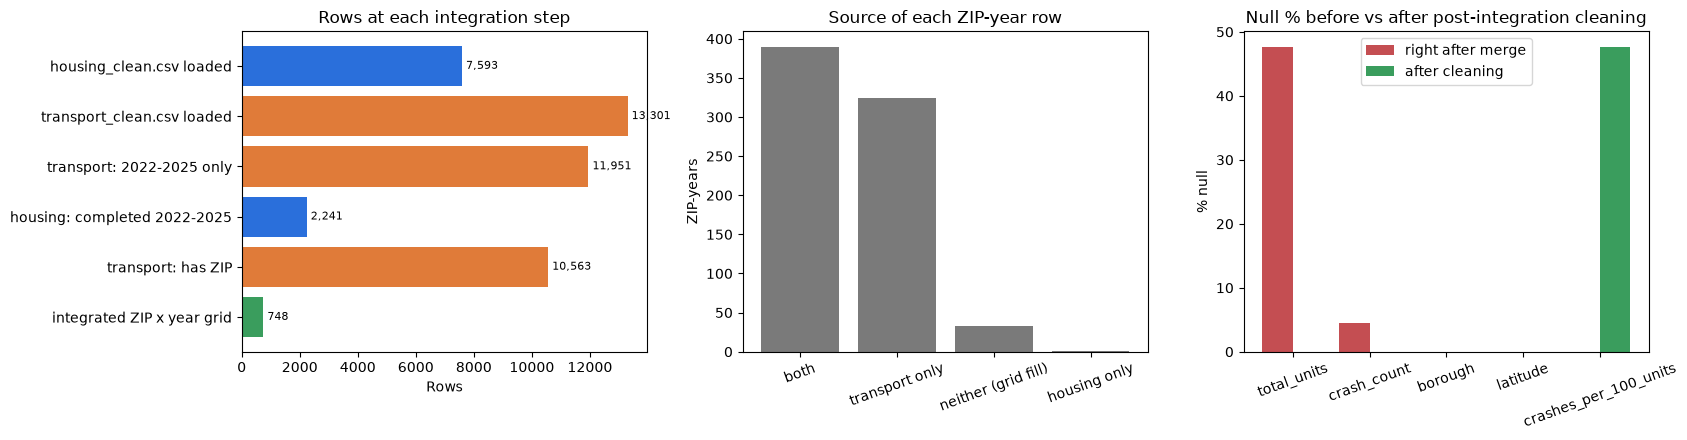

In [41]:
row_log_df = pd.DataFrame(row_log)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# (a) Rows at each step
colors = row_log_df['dataset'].map({'housing': '#2a6fdb', 'transport': '#e07b39', 'integrated': '#3a9d5d'})
axes[0].barh(row_log_df['step'], row_log_df['rows'], color=colors)
axes[0].invert_yaxis(); axes[0].set_xlabel('Rows'); axes[0].set_title('Rows at each integration step')
for i, v in enumerate(row_log_df['rows']):
    axes[0].text(v, i, f' {v:,}', va='center', fontsize=8)

# (b) Where the merged rows came from
src = integrated['match_source'].value_counts()
axes[1].bar(src.index.astype(str), src.values, color='#7a7a7a')
axes[1].set_title('Source of each ZIP-year row'); axes[1].set_ylabel('ZIP-years')
axes[1].tick_params(axis='x', rotation=20)

# (c) Null % before vs after post-integration cleaning
cols_show = ['total_units', 'crash_count', 'borough', 'latitude', 'crashes_per_100_units']
# borough/latitude/rate only exist after 5.2 and 5.4, so they have no "right after merge" value
nb = [null_before['total_units'], null_before['crash_count'], 0, 0, 0]
na = [null_after.get(c, 0) for c in cols_show]
x = np.arange(len(cols_show))
axes[2].bar(x - 0.2, np.nan_to_num(nb), 0.4, label='right after merge', color='#c44e52')
axes[2].bar(x + 0.2, na, 0.4, label='after cleaning', color='#3a9d5d')
axes[2].set_xticks(x, cols_show, rotation=20); axes[2].set_ylabel('% null')
axes[2].set_title('Null % before vs after post-integration cleaning'); axes[2].legend()
plt.tight_layout(); plt.show()

Note on chart (c): `borough`, `latitude` and the rate did not exist as single columns right after the merge
(they were created in 5.2 and 5.4), so their "before" bar is 0. The rate's remaining nulls are intentional:
ZIP-years with no completed units.

In [42]:
# Quick look at the cross-domain relationship (Members 1 and others will build the real charts)
city = integrated.groupby('year')[['total_units', 'crash_count']].sum()
print(city)
active = integrated[integrated['total_units'] > 0]
print('\nSpearman correlation, units vs crashes (ZIP-years with completions):',
      round(active['total_units'].corr(active['crash_count'], method='spearman'), 3))

      total_units  crash_count
year                          
2022        28757         2482
2023        41279         2655
2024        33460         2680
2025        38984         2746

Spearman correlation, units vs crashes (ZIP-years with completions): 0.303


## 7. Save

In [43]:
out_csv = CLEAN_DIR / 'integrated_zip_year.csv'
integrated.to_csv(out_csv, index=False)
row_log_df.to_csv(CLEAN_DIR / 'integration_row_log.csv', index=False)
print('Saved', out_csv, integrated.shape)

Saved data\clean\integrated_zip_year.csv (748, 27)


## Limitations of the integration

- **Crashes without a ZIP are dropped** (about 11% of 2022-2025 crashes, mostly on highways). Crash counts per ZIP are slightly low.
- **ZIP codes are postal routes, not neighbourhoods**: a few ZIPs straddle a borough line, and each ZIP gets one borough label (majority vote).
- **Affordable housing only**: the housing data covers HPD-counted affordable buildings, not all new construction, so a ZIP with 0 units may still have market-rate development.
- **Serious crashes only**: SIRTA records serious-injury and fatal crashes, not all crashes or traffic volume, so `crash_count` measures severe risk, not travel.
- **No population or traffic denominator**: busier ZIPs have more crashes simply because more people travel there. Comparisons between ZIPs are associations, not causes.
- **2026 excluded** because both files stop on 2026-06-30.
- The same building can appear in two projects (123 rows); its units are counted once per project, as HPD reports them.

## Prompts Used (Member 3)

**Tool:** AI assistant, 5-6 November 2026. Prompts are summarised; the AI's code was run and checked against the data before use, and I adapted it to the project.

| # | Task | Prompt (summary) | What the AI produced | What I did with it |
|---|------|------------------|----------------------|--------------------|
| 1 | Join design | Described the two datasets and asked which key and granularity suit a housing-versus-crash question | Suggested ZIP x year, with reasons and alternatives such as borough x year and spatial joins | Chose ZIP x year and wrote the justification |
| 2 | Join type | Asked which join to use when ZIPs have housing but no crashes or the reverse | Explained an outer join on a complete ZIP x year grid and filling counts with 0 | Implemented the full outer join and checked totals |
| 3 | Crashes without ZIP | Asked how to handle crashes with a missing ZIP | Nearest-ZIP imputation from coordinates, and dropping what cannot be placed | Applied it and documented the dropped share as a limitation |
| 4 | Post-integration cleaning | Asked for steps for new nulls, duplicate borough columns, dtypes and rate outliers | Code for borough majority vote, category columns, rates with flags, dtype fixes | Ran it, validated the totals, saved `integrated_zip_year.csv` |
| 5 | Charts 05 and 06 | Asked for a box plot by housing tier and a map of crash change with housing | `chart_05.py` and `chart_06.py` | Tested with filters and pushed them |

Prompts are summarised from my working sessions.

---
# Research questions and visualizations

# Member 4: App Integration, Charts 7–8 and RQ7–RQ8
Dataset: `data/clean/integrated_zip_year.csv` (ZIP × year, 2022–2025; housing = Affordable Housing Production by Building, transport = SIRTA serious crashes). Built by Member 3 from the cleaned housing and transportation files.

In [44]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Integrated ZIP x year dataset (produced by Member 3), already uploaded to this Colab session
DATA_PATH = "data/clean/integrated_zip_year.csv"
df_m4 = pd.read_csv(DATA_PATH, dtype={"zip_code": str})

print(df_m4.shape)
df_m4.head()

(748, 27)


,zip_code,borough,year,latitude,longitude,buildings_completed,projects_completed,total_units,new_construction_units,preservation_units,...,severe_injuries,non_severe_injuries,transport_category,crashes_per_100_units,deeply_affordable_share,injuries_per_crash,match_source,flag_rate_outlier,flag_small_unit_base,flag_units_outlier
0,10451,Bronx,2022,40.82069,-73.92309,3,3,544,544,0,...,28,4,Fatal crash recorded,5.15,0.257,1.14,both,False,False,False
1,10451,Bronx,2023,40.82069,-73.92309,12,6,2937,1063,1874,...,22,7,Serious injuries only,0.68,0.278,1.45,both,False,False,True
2,10451,Bronx,2024,40.82069,-73.92309,11,11,1683,1643,40,...,22,6,Fatal crash recorded,1.49,0.030,1.12,both,False,False,True
3,10451,Bronx,2025,40.82069,-73.92309,6,6,279,210,69,...,25,9,Fatal crash recorded,9.32,0.176,1.31,both,False,False,False
4,10452,Bronx,2022,40.83879,-73.92192,6,6,590,530,60,...,51,13,Fatal crash recorded,8.14,0.368,1.33,both,False,False,False


## RQ7 · Member 4
**Question:** In which boroughs, and in which years, were serious crashes highest relative to the amount of new affordable housing completed?

**Why it matters:** Helps planners see where new housing coincides with the heaviest crash burden, and whether that is changing.

**Variables:** `total_units` (housing), `crash_count` (transportation). ZIP-years are summed per borough and year, and the rate is total crashes ÷ total units × 100 (ratio of sums, so small ZIPs do not dominate). ZIP-years with 0 units are excluded because the rate is undefined.

**Visualization:** Heatmap (borough × year). A heatmap fits because it compares one rate across two categorical dimensions. Cells under 200 completed units are marked `*` and kept out of the colour scale.

**Finding:** Among boroughs with solid unit counts, Brooklyn has the highest rate in 2022 (9.9 crashes per 100 units), 2024 (7.7) and 2025 (6.8). In 2023 Brooklyn, Queens and Manhattan are about equal (~6). The Bronx rises from 3.4 to 5.2, partly because its completed units fell from 13.6k to 9.2k. Staten Island is unstable because it completes few units (67 to 364 per year).

**Limitations:** Units completed in a year is a flow, not the housing stock, so the rate is an indicator and not a true exposure measure. Small denominators are unstable. This shows association only, not causation.

In [45]:
# Independent check: the heatmap values must equal these (ZIP-years with units > 0, ratio of sums)
with_units = df_m4[df_m4.total_units > 0]
check_7 = with_units.groupby(["borough", "year"]).agg(crashes=("crash_count", "sum"),
                                                      units=("total_units", "sum"))
check_7["rate_per_100_units"] = (check_7.crashes / check_7.units * 100).round(1)
print("Crashes per 100 units:")
display(check_7["rate_per_100_units"].unstack("year"))
print("Units behind each cell:")
display(check_7["units"].unstack("year"))

Crashes per 100 units:


year,2022,2023,2024,2025
borough,,,,
Bronx,3.4,2.6,4.2,5.2
Brooklyn,9.9,6.1,7.7,6.8
Manhattan,7.3,5.9,4.2,4.8
Queens,4.9,6.0,7.6,4.1
Staten Island,3.8,29.9,15.9,7.8


Units behind each cell:


year,2022,2023,2024,2025
borough,,,,
Bronx,13637,18504,12108,9162
Brooklyn,6573,11099,8835,11297
Manhattan,3650,6315,8344,8294
Queens,4533,5294,4060,10116
Staten Island,364,67,113,115


In [49]:
with_units = df_m4[df_m4.total_units > 0]
g = with_units.groupby(["borough", "year"]).agg(crashes=("crash_count", "sum"), units=("total_units", "sum"))
g["rate_per_100_units"] = (g.crashes / g.units * 100).round(1)
g["rate_per_100_units"].unstack("year")

year,2022,2023,2024,2025
borough,,,,
Bronx,3.4,2.6,4.2,5.2
Brooklyn,9.9,6.1,7.7,6.8
Manhattan,7.3,5.9,4.2,4.8
Queens,4.9,6.0,7.6,4.1
Staten Island,3.8,29.9,15.9,7.8


## RQ8 · Member 4
**Question:** Are serious crashes more likely to be fatal in ZIP-years dominated by new construction than by preservation, or with no completions?

**Why it matters:** Tests whether the type of housing activity is linked to how deadly crashes are, not only how many there are.

**Variables:** `housing_category` (housing, assigned per ZIP-year by which type has more units), `fatal_crashes` and `crash_count` (transportation). The fatal share is pooled: total fatal crashes ÷ total crashes in each category.

**Visualization:** Bar chart with approximate 95% confidence intervals. Bars compare one share across three categories, and the error bars show whether the gaps are larger than noise.

**Finding:** No meaningful difference. The fatal share is 5.8% for new construction, 5.7% for no completions and 6.0% for preservation, and the gaps are within the error bars.

**Limitations:** Categories differ in size and ZIP mix. The confidence intervals treat crashes as independent, which is approximate. This shows association only, not causation.

In [50]:
# Independent check: bar heights must equal fatal_pct here
check_8 = df_m4.groupby("housing_category").agg(crashes=("crash_count", "sum"),
                                                fatal=("fatal_crashes", "sum"),
                                                zip_years=("year", "size"))
check_8["fatal_pct"] = (check_8.fatal / check_8.crashes * 100).round(1)
check_8

,crashes,fatal,zip_years,fatal_pct
housing_category,,,,
New Construction,5507,317,284,5.8
No completions,3157,181,357,5.7
Preservation,1899,114,107,6.0


## Dash app integration (Member 4)
- Loads the real integrated CSV on startup (ZIP padded to 5 digits, year as integer); the mock-data fallback was removed.
- Four dropdown filters (borough, year multi-select, housing category, transportation category) applied through `apply_filters`.
- "Generate Report" rebuilds all 12 charts from the filtered data and updates the summary line.
- Each chart is built through `chart_loader.py`; a chart that errors shows a placeholder instead of breaking the page.
- Bug fixed: selecting a year while "All" was still selected was ignored.
- Validation: the summary counts for 7 filter combinations were compared with independent pandas counts (for example Brooklyn + 2022 = 39 ZIP-year records across 39 ZIPs).
- Source: `app.py`, `chart_loader.py`, `charts/chart_07.py`, `charts/chart_08.py` in the GitHub repository.

## Prompts Used (Member 4)

**Tool:** Claude (Anthropic), used on 7–8 November 2026. Prompts are summarised; the AI's code was run, checked against the data and adapted by me before use.

| # | Task | Prompt (summary) | What the AI produced | What I did with it |
|---|------|------------------|----------------------|--------------------|
| 1 | Plan the Member 4 role | Shared the project description and the team task split, and asked which files were needed to integrate the real data into the Dash app and plug in all 12 charts. | A list of the files needed (`app.py`, `config.py`, `chart_loader.py`, the chart files, the integrated CSV, the data dictionary). | Sent those files and used the list as my checklist. |
| 2 | Check the integrated data | Asked for a way to confirm the integrated CSV matches the column names and types the app and charts expect. | `check_data.py`, which prints shape, dtypes, missing columns, years, duplicates, nulls and category values. | Ran it: 748 rows, 187 ZIPs, all expected columns present, no duplicate ZIP-years. No change to `config.py` was needed. |
| 3 | Validate the data independently | Asked how to be sure the data and the dashboard numbers are correct. | `verify_data.py`: 18 checks (ZIP format, NYC coordinate range, unit and crash arithmetic, recomputed derived columns, category consistency) plus expected summary counts for 7 filter combinations. | Ran it: all checks passed. I use its counts to test Generate Report. |
| 4 | Fix filter behaviour | Asked why the Year filter might misbehave with the "All" option, and how to make filters and Generate Report reliable. | A corrected `apply_filters` year block: if real years are selected alongside "All", the real years win. | Applied it. Verified with "2022 + 2023" = 374 records and "Brooklyn + 2022" = 39 records. |
| 5 | Dashboard theming and cleanup | Asked how to stop chart titles overlapping the plots and remove duplicated styling code. | A `style_figure()` helper used for every chart in the initial render and in Generate Report. | Applied it in `app.py`. |
| 6 | Remove mock data | Asked to remove the mock-data fallback because the real data is ready. | A `load_startup_data()` that reads the real CSV and fails loudly if it is missing, and removal of the mock banner. | Applied it and removed the `mock_data` import. |
| 7 | Design my two charts | Asked for two chart ideas that relate the housing and transportation datasets and avoid simple counts. | Options, from which I chose a borough × year heatmap of crashes per 100 completed units (RQ7) and fatal share of crashes by housing category (RQ8). | Wrote them as `chart_07.py` and `chart_08.py`. |
| 8 | Check my charts against the data | Pasted the recomputed tables and asked whether the charts were reliable. | Observations: Staten Island's rates rest on very few units, so unstable cells were marked and kept out of the colour scale; chart 8 differences are within noise, so 95% confidence intervals were added. | Applied the changes and compared the tooltips with `verify_my_charts.py` output. |
| 9 | Research questions and documentation | Asked what the description requires for research questions and where they go. | Guidance: 2 RQs per member, each with one chart answering it; put the text in the chart's `QUESTION`, the notebook and the README table. Templates for my two RQ cells. | Filled in RQ7 and RQ8 with my own findings and limitations.


---
# Member 5: Search Mode, Story Section, Charts 09 and 10

## Member 5 overview

**Output files:** `search_parser.py`, `story_section.py`, `charts/chart_09.py`, `charts/chart_10.py`, `app.py` (search box and story section)
**Data:** `data/clean/integrated_zip_year.csv` (187 ZIP codes x 4 years, 2022-2025, built by Member 3 from the housing dataset `hg8x-zxpr` and the SIRTA crash dataset `xeqp-qz8h`)

## Member 5 research questions (RQ9, RQ10)

**Research question 9:** Which ZIP codes had the most serious crashes relative to the amount of affordable housing they completed?
*Chart 09: horizontal bar chart of the top 10 ZIP codes by serious crashes per 100 completed units, coloured by borough.*

**Research question 10:** In ZIP codes where a larger share of new units are deeply affordable, are the serious crashes more injurious?
*Chart 10: scatter plot of deeply affordable share (x) against injuries per crash (y), one point per ZIP, sized by units completed, with a trend line and Spearman correlation.*

**Why these questions matter:** Chart 09 points planners to the ZIP codes where new homes sit in areas with many serious crashes. Chart 10 checks whether neighbourhoods built for the lowest incomes also face more severe crashes, which is an equity question.

## Member 5 design decisions decisions and justification

**Chart 09**
- **Sum, then divide.** Crashes and units are summed per ZIP over the selected rows before computing the rate. Averaging yearly rates would give a ZIP-year with 5 units the same weight as one with 500.
- **Minimum of 100 completed units.** A ZIP with very few units gives a huge, unstable rate, so those ZIPs are left out. The threshold is a judgement call, and the chart returns a message if no ZIP passes it.
- **Top 10 only** so the labels stay readable.

**Chart 10**
- **ZIP-level aggregation.** Each ZIP is summed over the selected years, so one dot is one neighbourhood and not one ZIP-year.
- **Minimum of 20 units and 3 crashes.** Injuries per crash is meaningless with 1 or 2 crashes.
- **Spearman, not Pearson.** The data is skewed with large outliers (a few ZIPs with thousands of units), and Spearman uses ranks so it is not dominated by them.
- **The chart prints "Association only, not cause"** so the reader does not read the trend line as causation.

## Member 5 search mode mode: why a rule-based parser

The project requires a search box where a query such as "Brooklyn 2022 new buildings" sets the filters.

**Approach:** keyword and regex matching in `search_parser.py`.
1. Borough: look for Bronx, Brooklyn, Manhattan, Queens or Staten Island in the lowercase text.
2. Year: regex `\b(20\d{2})\b`, keeping only years that exist in the data (2022-2025).
3. Housing category: words such as "new buildings", "new construction", "preservation" map to the dropdown values.
4. Transportation category: words such as "fatal", "injury", "safe" map to the dropdown values.
5. Longest keywords are checked first, so "staten island" is not confused with a shorter word.

**Alternatives considered:**
- *An LLM or NLP model:* more flexible, but needs an API key, adds cost and delay, and can return values that are not in the dropdowns. Our dropdown vocabulary is small and fixed, so rules are enough.
- *Fuzzy matching (typo tolerance):* useful, but it can match the wrong word, and we did not have time to validate it.

**Behaviour:** the search only fills the dropdowns. The charts update when the user clicks **Generate Report**, so the user can check the filters first. An empty query resets all filters, and an unrecognised query shows "No filters recognized".

**Limitation:** the parser only knows the words in its lists. A query with a synonym it does not know (for example "Flatbush") is not recognised.

In [51]:
# Locate the repository (clone only if the repo folder is not already available); no %cd, so later cells keep their paths
import os, sys
from pathlib import Path
roots=[Path.cwd(),*Path.cwd().parents]
REPO=next((p for p in roots if (p/"search_parser.py").is_file()),None)
if REPO is None:
    if not Path("nyc-housing-transport").exists():
        os.system("git clone -q https://github.com/ahmadtarek16007891/nyc-housing-transport.git")
    REPO=Path("nyc-housing-transport").resolve()
sys.path.insert(0,str(REPO))
print("Repo:",REPO)

Repo: d:\nyc-housing-transport


In [52]:
import pandas as pd

import config
from search_parser import parse_query
import charts.chart_09 as chart_09
import charts.chart_10 as chart_10

df_m5 = pd.read_csv(config.DATA_PATH, dtype={"zip_code": str})
print(df_m5.shape)
df_m5.head(3)

(748, 27)


,zip_code,borough,year,latitude,longitude,buildings_completed,projects_completed,total_units,new_construction_units,preservation_units,...,severe_injuries,non_severe_injuries,transport_category,crashes_per_100_units,deeply_affordable_share,injuries_per_crash,match_source,flag_rate_outlier,flag_small_unit_base,flag_units_outlier
0,10451,Bronx,2022,40.82069,-73.92309,3,3,544,544,0,...,28,4,Fatal crash recorded,5.15,0.257,1.14,both,False,False,False
1,10451,Bronx,2023,40.82069,-73.92309,12,6,2937,1063,1874,...,22,7,Serious injuries only,0.68,0.278,1.45,both,False,False,True
2,10451,Bronx,2024,40.82069,-73.92309,11,11,1683,1643,40,...,22,6,Fatal crash recorded,1.49,0.030,1.12,both,False,False,True


## Member 5 search parser tests the search parser

Eight test queries, including a year-only query, an unknown word, an empty string, a year outside the data, and a query that matches no rows.

In [53]:
test_queries = [
    "Brooklyn 2022 new buildings",
    "queens fatal 2024",
    "2023",
    "bronx preservation",
    "Manhattan serious injuries 2022 2025",
    "Staten Island 2019",   # year not in the data, so it is ignored
    "pizza",                # nonsense, nothing recognised
    "",                     # empty, resets the filters
]

rows = []
for query in test_queries:
    filters, recognised = parse_query(query)
    rows.append({
        "query": query,
        "recognised": ", ".join(recognised) or "nothing",
        "borough": filters["borough"],
        "year": filters["year"],
        "housing": filters["housing_category"],
        "transport": filters["transportation_category"],
    })
pd.DataFrame(rows)

,query,recognised,borough,year,housing,transport
0,Brooklyn 2022 new buildings,"Brooklyn, 2022, New Construction",Brooklyn,[2022],New Construction,__ALL__
1,queens fatal 2024,"Queens, 2024, Fatal crash recorded",Queens,[2024],__ALL__,Fatal crash recorded
2,2023,2023,__ALL__,[2023],__ALL__,__ALL__
3,bronx preservation,"Bronx, Preservation",Bronx,[__ALL__],Preservation,__ALL__
4,Manhattan serious injuries 2022 2025,"Manhattan, 2022, 2025, Serious injuries only",Manhattan,"[2022, 2025]",__ALL__,Serious injuries only
5,Staten Island 2019,Staten Island,Staten Island,[__ALL__],__ALL__,__ALL__
6,pizza,nothing,__ALL__,[__ALL__],__ALL__,__ALL__
7,,nothing,__ALL__,[__ALL__],__ALL__,__ALL__


**Results:** the first five queries set the expected dropdowns. "Staten Island 2019" sets only the borough because 2019 is outside 2022-2025. "pizza" and the empty string return all-default filters, and the website shows "No filters recognized" or "Filters reset" for them.

## Member 5 charts 09 and 10 on the full data

In [54]:
chart_09.build_figure(df_m5, {}).show()

In [55]:
chart_10.build_figure(df_m5, {}).show()

## Member 5 findings and limitations (RQ9, RQ10)

**RQ9 (chart 09).** Of the ZIPs with at least 100 completed units, the highest serious-crash rates per 100 completed units (2022-2025) are in Brooklyn (ZIP 11229 about 79, 11234 about 77, 11223 about 63, 11220 about 54), followed by Manhattan (10022 about 56, 10013 about 49), Queens (11423 about 55, 11373 about 51, 11369 about 48) and Staten Island (10305 about 49). Brooklyn holds four of the top ten.

**RQ10 (chart 10).** Across 122 ZIPs, the Spearman correlation between deeply affordable share and injuries per crash is about 0.14. This is a weak positive association, so there is little evidence that deeply affordable neighbourhoods face more injurious crashes.

**Limitations.**
- Association only, not cause; no traffic or population denominator.
- Thresholds (100 units for chart 09; 20 units and 3 crashes for chart 10) are judgement calls and exclude small ZIPs.
- Crashes without a ZIP (about 11%) are dropped, and ZIPs are not neighbourhoods.
- Search is rule-based: unknown words such as "Flatbush" are not recognised.

**Story section** (`story_section.py`): question, data and integration, findings, limits and benefit to NYC are shown in the app below the charts.

## Prompts Used (Member 5)

**Tool:** Claude (Anthropic), used on 8-9 November 2026. Prompts are summarised. The AI's code was run and tested against our data before use, and I adapted the text to our project.

| # | Task | Prompt (summary) | What the AI produced | What I did with it |
|---|------|------------------|----------------------|--------------------|
| 1 | Understand my role | Shared the project description PDF, the dataset catalog PDF and our team task list, said I am Member 5, and asked exactly what to do step by step | A step-by-step plan: finish the search parser and CSS, redeploy, write the story section, then hand off to Member 6 | Used it as my to-do list and checked it against the deadline |
| 2 | Check the repo and simplify the plan | Uploaded our GitHub repo as a zip and asked for the simple version of what I actually have to do | Found that `app.py` had no search box and no story section, and wrote `search_parser.py`, `story_section.py` and the `app.py` changes, then tested 8 queries | Added the files to the repo and checked the search behaviour |
| 3 | Git branch | Asked whether to add the new files to the main branch | Told me to pull first, then copy in the files and push, so I would not overwrite teammates' work | Ran `git pull` before copying files |
| 4 | Charts 09 and 10 | Asked for charts 9 and 10 to replace the generic placeholder charts | Wrote `chart_09.py` (top ZIPs by crashes per 100 affordable units) and `chart_10.py` (deeply affordable share vs injuries per crash), tested with several filters and an empty selection | Added both files to `charts/` and pushed `chart_09.py` to main |
| 5 | Saving work | Asked whether committing after each chart saves the work | Explained that a commit saves locally and a push sends it to GitHub and Render | Used `git add`, `commit` and `push` |
| 6 | Checking progress | Sent a screenshot of `chart_09.py` on GitHub and asked what to do next, then asked if chart 9 was done | Confirmed the push worked and listed what to check on the live site | Checked the file on GitHub |
| 7 | Testing the search | Asked exactly what to type to test the search box, step by step | A table of 6 test queries with the expected dropdown values and messages | Used the table as my test plan |
| 8 | Running the app locally | Asked how to run and test the app in VS Code, then sent screenshots of the `pip`, `py` and `python` errors | Steps to install Python with PATH ticked and run `python -m pip install` and `python app.py` | Followed the steps to set up Python |
| 9 | Notebook section | Asked for the Member 5 section for the Colab notebook | This notebook: research questions, design justification, parser explanation, test cell, findings, limitations | Reviewed it and adapted it |

---
# Member 6: Validation, Documentation, Chart 11 and Chart 12

This section preserves the validation snapshots created in Members 1–3's sections and adds Member 6's own two visualizations. It is designed to run after the previous notebook sections, from top to bottom.

**Important:** the raw-before and cleaned-after dataframes are used for cleaning comparisons. The IQR outliers in the source cleaning logic are flagged and retained; the plots below do not imply that every flagged extreme value was deleted.

## Member 6 validation: cleaning and integration evidence

The team plan asks for before/after row counts, null percentages, and outlier boxplots. The earlier notebook used generic names such as `null_before`, which are reused by different members. The small snapshots added above (`housing_null_pct_before`, `transport_null_pct_before`, etc.) preserve each stage so these comparisons cannot silently use another member's statistics.

       dataset           stage  rows  removed_from_raw
       Housing Before cleaning  9551              1958
       Housing  After cleaning  7593              1958
Transportation Before cleaning 13310                 9
Transportation  After cleaning 13301                 9


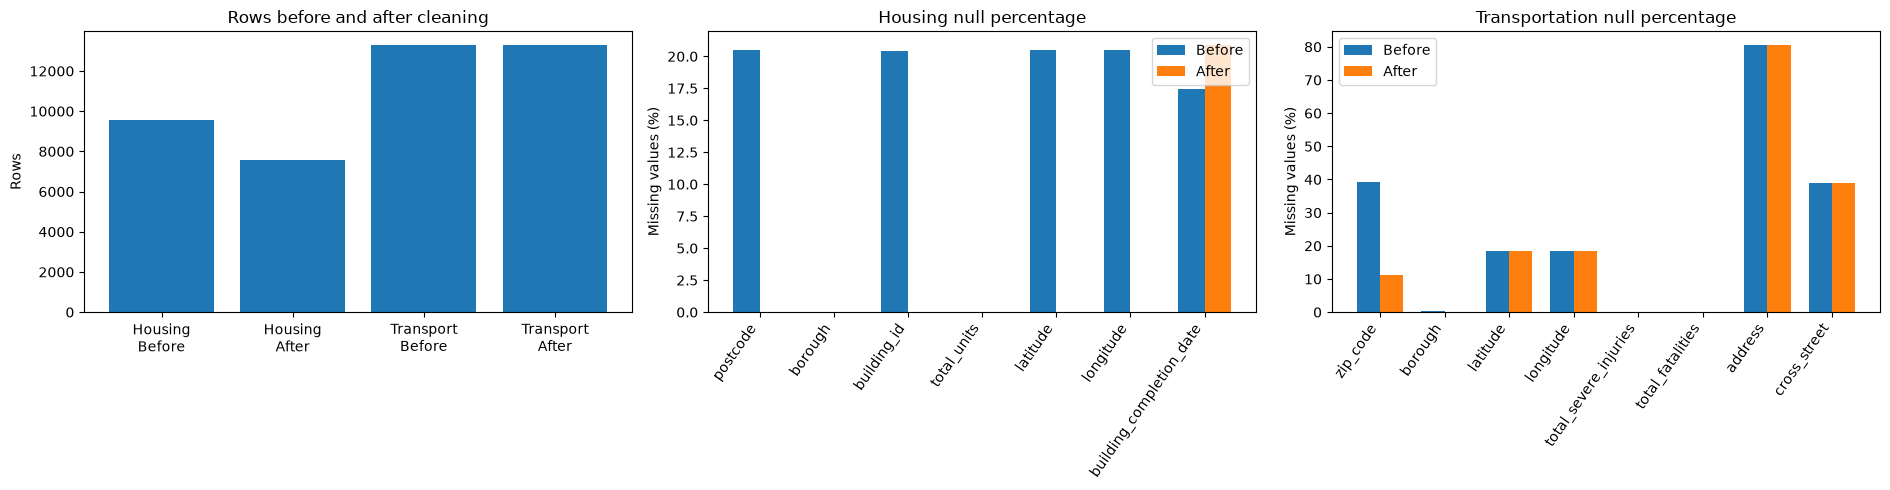

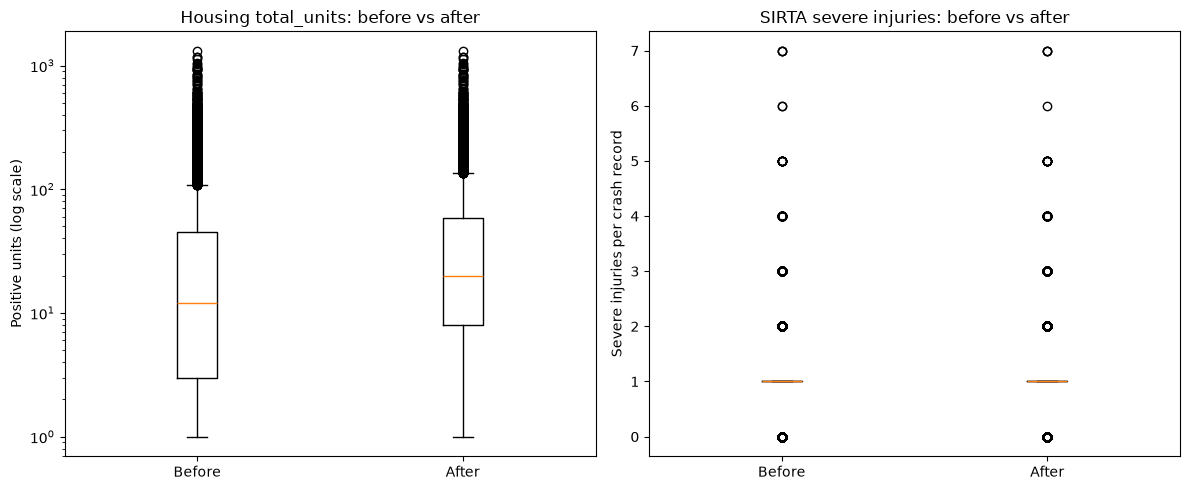

Post-integration null percentages (only shared metric columns):


,before_join_cleaning,after_post_integration_cleaning
buildings_completed,47.7,0.0
total_units,47.7,0.0
crash_count,4.5,0.0
severe_injuries,4.5,0.0
non_severe_injuries,4.5,0.0
fatalities,4.5,0.0


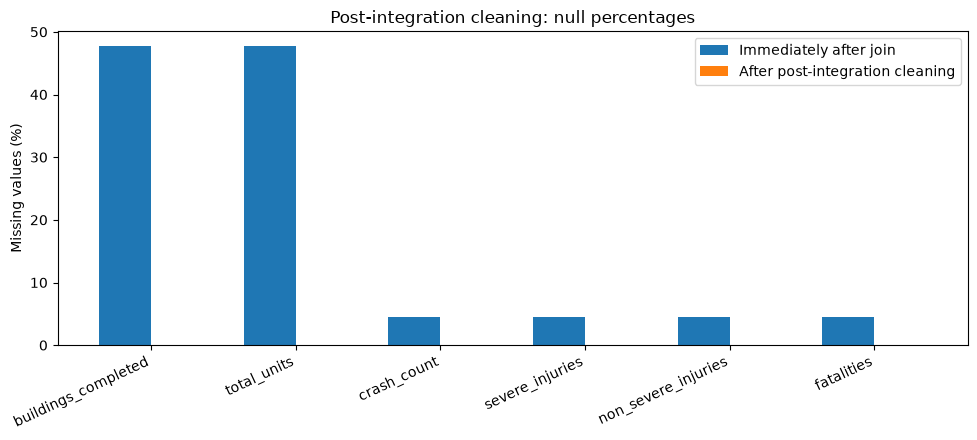

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# (1) Row retention: values come from the actual raw and cleaned dataframes.
row_validation = pd.DataFrame({
    "dataset": ["Housing", "Housing", "Transportation", "Transportation"],
    "stage": ["Before cleaning", "After cleaning", "Before cleaning", "After cleaning"],
    "rows": [len(h_raw), len(h), len(df_raw), len(t)],
})
row_validation["removed_from_raw"] = row_validation["dataset"].map({
    "Housing": len(h_raw) - len(h),
    "Transportation": len(df_raw) - len(t),
})
print(row_validation.to_string(index=False))

# (2) Null percentages before vs after. Compare only fields present at both stages.
def _paired_nulls(before_series, after_series, columns, rename_before=None):
    before_series = before_series.copy()
    if rename_before:
        before_series = before_series.rename(index=rename_before)
    rows = []
    for column in columns:
        if column in before_series.index and column in after_series.index:
            rows.append({
                "column": column,
                "before": float(before_series[column]),
                "after": float(after_series[column]),
            })
    return pd.DataFrame(rows)

housing_null_comparison = _paired_nulls(
    housing_null_pct_before, housing_null_pct_after,
    ["postcode", "borough", "building_id", "total_units", "latitude", "longitude", "building_completion_date"],
)
transport_rename = {}
if "COL" in globals():
    if COL.get("borough"):
        transport_rename[COL["borough"]] = "borough"
    if COL.get("zip"):
        transport_rename[COL["zip"]] = "zip_code"
transport_null_comparison = _paired_nulls(
    transport_null_pct_before, transport_null_pct_after,
    ["zip_code", "borough", "latitude", "longitude", "total_severe_injuries", "total_fatalities", "address", "cross_street"],
    rename_before=transport_rename,
)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
row_labels = ["Housing\nBefore", "Housing\nAfter", "Transport\nBefore", "Transport\nAfter"]
row_values = [len(h_raw), len(h), len(df_raw), len(t)]
axes[0].bar(row_labels, row_values)
axes[0].set_title("Rows before and after cleaning")
axes[0].set_ylabel("Rows")
axes[0].tick_params(axis="x", rotation=0)

for axis, comparison, title in [
    (axes[1], housing_null_comparison, "Housing null percentage"),
    (axes[2], transport_null_comparison, "Transportation null percentage"),
]:
    if not comparison.empty:
        x = np.arange(len(comparison))
        axis.bar(x - 0.18, comparison["before"], width=0.36, label="Before")
        axis.bar(x + 0.18, comparison["after"], width=0.36, label="After")
        axis.set_xticks(x, comparison["column"], rotation=55, ha="right")
        axis.legend()
    else:
        axis.text(0.5, 0.5, "No comparable columns found", ha="center", va="center")
    axis.set_title(title)
    axis.set_ylabel("Missing values (%)")
plt.tight_layout()
plt.show()

# (3) Outlier/distribution comparison for one important numeric field per dataset.
# Positive-only values are used on the log scale; flagged IQR observations remain present.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
housing_raw_units = pd.to_numeric(h_raw.get("total_units"), errors="coerce")
housing_clean_units = pd.to_numeric(h.get("total_units"), errors="coerce")
transport_raw_severe = pd.to_numeric(df_raw.get("total_severe_injuries"), errors="coerce")
transport_clean_severe = pd.to_numeric(t.get("total_severe_injuries"), errors="coerce")

axes[0].boxplot([
    housing_raw_units[housing_raw_units > 0].dropna(),
    housing_clean_units[housing_clean_units > 0].dropna(),
], tick_labels=["Before", "After"], showfliers=True)
axes[0].set_yscale("log")
axes[0].set_title("Housing total_units: before vs after")
axes[0].set_ylabel("Positive units (log scale)")

axes[1].boxplot([
    transport_raw_severe[transport_raw_severe >= 0].dropna(),
    transport_clean_severe[transport_clean_severe >= 0].dropna(),
], tick_labels=["Before", "After"], showfliers=True)
axes[1].set_title("SIRTA severe injuries: before vs after")
axes[1].set_ylabel("Severe injuries per crash record")
plt.tight_layout()
plt.show()

# (4) Post-integration null change for columns that existed on both sides of the join.
shared_integration_columns = [
    column for column in ["buildings_completed", "total_units", "crash_count", "severe_injuries", "non_severe_injuries", "fatalities"]
    if column in integration_null_pct_before.index and column in integration_null_pct_after.index
]
integration_null_comparison = pd.DataFrame({
    "before_join_cleaning": integration_null_pct_before[shared_integration_columns],
    "after_post_integration_cleaning": integration_null_pct_after[shared_integration_columns],
})
print("Post-integration null percentages (only shared metric columns):")
display(integration_null_comparison.round(2))

fig, axis = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(integration_null_comparison))
axis.bar(x - 0.18, integration_null_comparison["before_join_cleaning"], width=0.36, label="Immediately after join")
axis.bar(x + 0.18, integration_null_comparison["after_post_integration_cleaning"], width=0.36, label="After post-integration cleaning")
axis.set_xticks(x, integration_null_comparison.index, rotation=25, ha="right")
axis.set_ylabel("Missing values (%)")
axis.set_title("Post-integration cleaning: null percentages")
axis.legend()
plt.tight_layout()
plt.show()

### Validation interpretation

- The housing cleaning output contains **7,593 rows**, compared with **9,551 rows** before cleaning (1,958 removed). The raw counts are captured from the notebook's actual dataframes.
- The transportation sample contains **13,310 rows** before cleaning and **13,301 rows** after cleaning (9 removed). ZIP and borough imputation/retention decisions are documented in Member 2's section.
- The integrated table is a complete ZIP × year grid for 187 ZIP codes and four years (748 rows). New missing values in count metrics are filled with zero only under the documented complete-register assumption; derived rates remain missing when their denominator is zero.
- IQR-flagged extreme values are retained when the project cleaning rule says they may be genuine events. The boxplots are distribution checks, not proof that all statistical outliers were removed.

## Member 6 research questions and visualizations

### RQ11 — Which housing-production indicators are most strongly associated with serious-crash outcomes across ZIP-years?

**Why it matters:** Comparing multiple housing indicators with serious-crash counts and injury outcomes helps planners identify where housing activity and serious street-safety burden are observed together.

**Visualization:** Chart 11 is a cross-domain Spearman correlation heatmap. It uses the eight available housing activity measures against five SIRTA outcomes. Spearman rank correlation is used because the ZIP-year totals are skewed and contain many zeros. ZIP code, year, coordinates, category labels, and derived ratios are excluded from the correlation matrix.

**Finding from the supplied integrated CSV:** The strongest displayed pair is `projects_completed` and `crash_count` (Spearman ρ ≈ **0.620**, n = **748**). `buildings_completed` and `crash_count` are also positively associated (ρ ≈ **0.602**). The relationship is weaker for fatal crashes; the strongest housing metric against `fatal_crashes` is `units_started` (ρ ≈ **0.314**).

**Limitations:** These are ZIP-year rank associations, not causal effects. Raw counts are influenced by population, traffic volume, road length, and ZIP area; none of those exposure denominators is present. Affordable-housing production is not a measure of all construction.

In [58]:
# Load Member 6's chart modules by path so this cell works without changing app imports.
from importlib.util import spec_from_file_location, module_from_spec
from pathlib import Path
import sys

candidate_roots = [Path.cwd(), *Path.cwd().parents]
repo_root = next((path for path in candidate_roots if (path / "charts" / "chart_11.py").is_file()), None)
if repo_root is None:
    raise FileNotFoundError("Could not locate charts/chart_11.py. Add Member 6's chart files to the repository first.")

def _load_chart_module(module_name, file_path):
    module_spec = spec_from_file_location(module_name, file_path)
    if module_spec is None or module_spec.loader is None:
        raise ImportError(f"Could not load {file_path}")
    module = module_from_spec(module_spec)
    module_spec.loader.exec_module(module)
    return module

member6_chart11 = _load_chart_module("member6_chart11", repo_root / "charts" / "chart_11.py")
member6_chart12 = _load_chart_module("member6_chart12", repo_root / "charts" / "chart_12.py")

# 'integrated' is built in Member 3's integration section above.
df_member6 = integrated.copy()
chart11_figure = member6_chart11.make_chart_11(df_member6)
chart12_figure = member6_chart12.make_chart_12(df_member6)
chart11_figure.show()
chart12_figure.show()

### RQ12 — How does serious-crash burden and fatal-crash share vary by borough and dominant housing activity?

**Why it matters:** A borough-by-activity view adds a spatial breakdown to the overall housing-category comparison and can help prioritize further street-safety investigation.

**Visualization:** Chart 12 is a treemap. Rectangle area represents the pooled number of ZIP-coded serious crashes for each borough × housing-category segment. Color represents the pooled fatal-crash share (`fatal_crashes ÷ crash_count × 100`), calculated as a ratio of sums rather than an average of ZIP-year percentages.

**Finding from the supplied integrated CSV:** Brooklyn's New Construction segment has the largest serious-crash count (**2,488**). Queens' Preservation segment has the highest fatal-crash share (**about 8.1%**, 22 fatal crashes among 270 serious crashes), while Bronx ZIP-years with No completions are about **7.2%** (11 of 153). Those smaller segments should be interpreted cautiously.

**Limitations:** The treemap's size encodes raw serious-crash volume, not a population- or traffic-adjusted rate. `housing_category` is assigned by the larger completed-unit type within each ZIP-year; “No completions” means no HPD-recorded affordable units completed in that ZIP-year, not that no other housing development exists. Grouped results are associative, not causal.

## Member 6 final quality assurance checklist

Run these checks after the chart files and the real integrated CSV are in the repository:

1. Run this notebook from the first cell to the final cell without errors.
2. Run `python member6_validation.py` from the repository root; confirm it reports **19 passed, 0 failed** for the supplied data.
3. Confirm `charts/chart_11.py` and `charts/chart_12.py` both expose `TITLE`, `QUESTION`, `make_chart_XX(df)`, and `build_figure(df, filters)`.
4. Open the Dash app and test both new charts with default filters, each borough, each year, and filters returning no rows.
5. Check all 12 chart modules, search parsing, dropdowns, Generate Report, story text, and empty-result messaging on the deployed site.
6. Replace the README placeholders with the actual six member IDs, repository URL, deployment URL, and verified contribution notes.
7. Send the final submission email to `ICS503Data@gmail.com` with all member IDs, the repository link, deployment link, and both dataset links. Keep a screenshot of the sent email.

The notebook, chart files, and validation report do not verify that the website has been deployed or that the final email has been sent; those actions require the team accounts and must be completed by the team.

## Member 6 prompt log

**Tool:** ChatGPT (OpenAI), 9 November 2026.

**Prompt (summary):** I provided the Milestone 1 team plan and asked for the Member 6 tasks to be implemented against the actual housing-clean, transport-clean, integrated ZIP-year CSVs, the existing notebook, `app.py`, and `chart_loader.py`. The implementation was required to follow the current repository structure, use actual integrated columns, and avoid inventing validation statistics.

**What the AI produced:** `charts/chart_11.py`, `charts/chart_12.py`, `member6_validation.py`, this notebook section, a README, `.gitignore`, and `requirements.txt`.

**Verification/adaptation:** The chart modules were imported and executed against all 748 integrated ZIP-year rows; both returned Plotly figures and both empty-data fallbacks were tested. The validation script was run against the three supplied CSV files and returned **19 passed, 0 failed**. The team must still review the code, run the complete notebook and app in its own repository, and confirm deployment, member IDs, contributions, and submission.